# Tugas Take-Home Sesi 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Mata kuliah:** Deep Learning — Sesi 05 *Advanced CNNs and Transfer Learning*
**Nama / NIM:** Nicholas Salim / 2802420776

## Tujuan eksperimen
Membandingkan empat kondisi pelatihan ResNet-18 pada subset 10 kelas Oxford-IIIT Pet dengan protokol yang seragam:

| Kode | Kondisi | Ringkasan |
|---|---|---|
| B1 | Baseline from scratch | `weights=None`, seluruh parameter dilatih |
| B2 | Feature extraction | backbone pretrained dibekukan, hanya `fc` (512→10) dilatih |
| B3 | Progressive fine-tuning | `layer4` + `fc` dibuka; LR diferensial 1e-4 / 1e-3 |
| B4 | Uji kontrol augmentasi | kondisi B3 dijalankan **tanpa** vs **dengan** augmentasi |
| B5 | Bonus | EfficientNet-B0 dengan konfigurasi terbaik (dipilih berdasarkan *validation*) |

## Cara menjalankan
1. Buka di Google Colab → `Runtime > Change runtime type > T4 GPU`.
2. `Runtime > Run all`. Saat diminta, izinkan akses Google Drive (artefak disimpan ke `MyDrive/Tugas05_DL/outputs` agar tidak hilang bila runtime terputus).
3. Bila runtime terputus, jalankan ulang `Run all`: dengan `resume=True`, kondisi yang sudah selesai dimuat dari Drive dan tidak dilatih ulang. Konsekuensinya, output sel untuk kondisi yang dimuat ulang hanya berisi baris `[RESUME]`; log per-epoch-nya tetap ada di `history_<kode>.csv`. Untuk notebook final yang lengkap, idealnya lakukan satu run bersih: hapus folder `MyDrive/Tugas05_DL/outputs`, lalu `Run all`.
4. Setelah selesai: `File > Download > Download .ipynb` (notebook beserta output) dan unduh `outputs_bundle.zip` dari sel terakhir.

## Prinsip integritas yang ditegakkan oleh kode
* Split dilakukan di level **indeks** dengan stratifikasi; *assert* memastikan train/val/test saling lepas.
* Augmentasi hanya pada DataLoader train; val/test selalu deterministik.
* Early stopping & pemilihan checkpoint memakai **validation loss**. Test set dievaluasi **sekali** per kondisi, setelah checkpoint terbaik dipulihkan.
* Pemilihan "model terbaik" (untuk B5, confusion matrix, failure analysis) memakai metrik **validation**, bukan test.
* Semua tabel/grafik dibangkitkan dari berkas log (`results/*.csv|json`), bukan diketik manual.

## 1. Import library dan pemeriksaan lingkungan

In [1]:
import os, sys, json, time, copy, random, platform, hashlib, shutil, warnings
from pathlib import Path

# Harus di-set sebelum CUDA diinisialisasi agar operasi cuBLAS dapat deterministik.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models, transforms, datasets
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

IN_COLAB = "google.colab" in sys.modules
SMOKE_TEST = os.environ.get("TUGAS05_SMOKE", "0") == "1"   # hanya untuk uji struktur di luar Colab

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ENV_INFO = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": Image.__version__,
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "cuda_version": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "in_colab": IN_COLAB,
    "smoke_test": SMOKE_TEST,
}
for k, v in ENV_INFO.items():
    print(f"{k:>14}: {v}")

if SMOKE_TEST:
    print("\n" + "!" * 78)
    print("SMOKE TEST MODE: dataset tiruan, bobot acak, 2 epoch. ANGKA DI BAWAH BUKAN HASIL EKSPERIMEN.")
    print("!" * 78)
elif DEVICE.type != "cuda":
    warnings.warn("GPU tidak terdeteksi. Aktifkan GPU T4: Runtime > Change runtime type.")

        python: 3.13.15
      platform: Linux-6.6.122+-x86_64-with-glibc2.39
         torch: 2.11.0+cu130
   torchvision: 0.26.0+cu130
         numpy: 2.1.3
        pandas: 2.2.3
  scikit_learn: 1.6.1
    matplotlib: 3.10.0
        pillow: 11.3.0
        device: cuda
      gpu_name: Tesla T4
  cuda_version: 13.0
 cudnn_version: 92700
      in_colab: True
    smoke_test: False


## 2. Konfigurasi: seed, device, hyperparameter, lokasi penyimpanan

Keputusan protokol (dicatat juga di `results/config.json`):

* **Hyperparameter wajib dari PDF:** input 224×224, normalisasi ImageNet, batch 32, AdamW, CrossEntropyLoss, early stopping pada *validation loss*.
* **Patience = 5** (batas atas rentang 3–5): val set hanya ±300 citra, sehingga val loss cukup berisik; patience 3 berisiko menghentikan B1 terlalu dini.
* **`max_epochs = 40`** sama untuk semua kondisi (tidak ditentukan PDF).
* **LR B1 = 1e-3** (tidak ditentukan PDF): sama dengan LR head, agar tidak ada kondisi yang di-*tuning* sepihak.
* **`weight_decay = 1e-2`** untuk semua kondisi (mengikuti starter code PDF).
* **`num_workers = 2`** tetap: aliran bilangan acak augmentasi berasal dari worker DataLoader, sehingga hasil hanya dapat diulang bila `num_workers` (dan GPU) sama.
* **Augmentasi B1–B3:** pipeline augmentasi starter code (sama untuk ketiganya). B4 menjalankan ulang kondisi B3 tanpa vs dengan augmentasi.
* **Checkpoint** = epoch dengan val loss terendah. **Epoch konvergen** = indeks epoch tersebut. **Val accuracy** dilaporkan pada checkpoint itu.

In [2]:
SEED = 42

CFG = {
    "seed": SEED,
    "num_classes": 10,
    "n_cat_classes": 5,
    "n_dog_classes": 5,
    "split_train_val_test": [0.70, 0.15, 0.15],
    "resize": 256,
    "img_size": 224,
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
    "batch_size": 32,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "weight_decay": 1e-2,
    "lr_scratch": 1e-3,        # B1 (seluruh jaringan)
    "lr_head": 1e-3,           # fc / classifier
    "lr_backbone_ft": 1e-4,    # layer4 (B3/B4) atau blok akhir EfficientNet (B5)
    "max_epochs": 40,
    "patience": 5,
    "min_delta": 0.0,
    "early_stopping_monitor": "val_loss",
    "checkpoint_rule": "epoch dengan val_loss terendah (bobot dipulihkan sebelum evaluasi test)",
    "best_condition_rule": "val_acc tertinggi pada checkpoint; seri -> val_loss terendah",
    "eval_train_clean": True,  # evaluasi ulang train set tanpa augmentasi tiap epoch (untuk generalization gap)
    "num_workers": 2,
    "amp": False,              # fp32 penuh agar sederhana dan lebih deterministik
    "cache_images": True,      # simpan citra yang sudah di-Resize(256) di RAM (hasil identik, lebih cepat)
    "run_b5": True,
    "run_c5": True,
    "resume": True,
}

if SMOKE_TEST:
    CFG.update({"max_epochs": int(os.environ.get("TUGAS05_MAX_EPOCHS", 2)), "patience": 1,
                "num_workers": int(os.environ.get("TUGAS05_WORKERS", 0))})
# Hook uji kegagalan: HANYA aktif dalam smoke test (mis. TUGAS05_SIMULATE_FAIL="B3,B5,C5").
SIMULATE_FAIL = set(os.environ.get("TUGAS05_SIMULATE_FAIL", "").split(",")) if SMOKE_TEST else set()

# ---- Lokasi penyimpanan -----------------------------------------------------
USE_DRIVE = IN_COLAB and not SMOKE_TEST
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/Tugas05_DL/outputs")
else:
    OUT_DIR = Path(os.environ.get("TUGAS05_OUT_DIR", "./outputs"))
DATA_ROOT = Path(os.environ.get("TUGAS05_DATA_ROOT", "/content/data" if IN_COLAB else "./data"))

RES_DIR, FIG_DIR, CKPT_DIR = OUT_DIR / "results", OUT_DIR / "figures", OUT_DIR / "checkpoints"
for d in (RES_DIR, FIG_DIR, CKPT_DIR, DATA_ROOT):
    d.mkdir(parents=True, exist_ok=True)
print("OUT_DIR  :", OUT_DIR.resolve())
print("DATA_ROOT:", DATA_ROOT.resolve())


def set_seed(seed: int = SEED):
    # Seed Python, NumPy, PyTorch (CPU & semua GPU) + cuDNN deterministik.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# warn_only=True: beberapa kernel CUDA (mis. backward AdaptiveAvgPool2d) tidak punya versi
# deterministik. PyTorch akan memberi peringatan, bukan error. Artinya determinisme penuh
# di GPU TIDAK dijamin; selisih kecil antar-run tetap mungkin.
torch.use_deterministic_algorithms(True, warn_only=True)
set_seed(SEED)

with open(RES_DIR / "config.json", "w") as f:
    json.dump({"config": CFG, "env": ENV_INFO}, f, indent=2)

Mounted at /content/drive
OUT_DIR  : /content/drive/MyDrive/Tugas05_DL/outputs
DATA_ROOT: /content/data


## 3. Download dan inspeksi dataset

**Hasil verifikasi API `torchvision.datasets.OxfordIIITPet`** (dicek dari source code dan diuji lagi di sel ini):

* `split` hanya `"trainval"` (3.680 citra) atau `"test"` (3.669 citra). Untuk mendapat ±200 citra/kelas seperti di PDF, **kedua split resmi digabung**, lalu di-split ulang 70/15/15 secara stratified.
* Label `category` = `CLASS-ID − 1` dari berkas anotasi; `ds.classes` diurutkan berdasarkan label → indeks `i` ↔ `ds.classes[i]`.
* Nama kelas di-*title-case*, sehingga kapitalisasi `ds.classes` **tidak bisa** dipakai untuk membedakan kucing/anjing. Spesies ditentukan dari nama file asli (konvensi dataset: nama file ras kucing berawalan huruf kapital), lalu **diverifikasi silang** dengan kolom `SPECIES` di `annotations/list.txt` (1 = kucing, 2 = anjing).
* Path dan label diambil dari atribut `_images` / `_labels` (atribut privat). Karena itu ada *assert*, dan isinya dicocokkan dengan berkas anotasi.

In [3]:
def load_pet_splits(root, max_attempts=3):
    # Unduh + muat kedua split resmi. Bila unduhan/ekstraksi parsial (runtime putus saat download),
    # folder dihapus lalu diunduh ulang. torchvision hanya memeriksa keberadaan folder, bukan isinya.
    base = Path(root) / "oxford-iiit-pet"
    last_err = None
    for attempt in range(1, max_attempts + 1):
        try:
            tv = datasets.OxfordIIITPet(root=str(root), split="trainval", target_types="category", download=True)
            te = datasets.OxfordIIITPet(root=str(root), split="test", target_types="category", download=True)
            missing = [p for p in list(tv._images) + list(te._images) if not Path(p).exists()]
            if missing:
                raise RuntimeError(f"{len(missing)} berkas citra hilang (ekstraksi tidak lengkap?), contoh: {missing[:3]}")
            return tv, te
        except Exception as e:
            last_err = e
            print(f"[percobaan {attempt}/{max_attempts}] gagal memuat dataset: {type(e).__name__}: {e}")
            if SMOKE_TEST:
                raise
            if base.exists():
                shutil.rmtree(base)   # hapus unduhan/ekstraksi parsial sebelum mencoba lagi
            time.sleep(10 * attempt)
    raise RuntimeError("Dataset gagal diunduh setelah beberapa percobaan. Cek koneksi ke "
                       "https://www.robots.ox.ac.uk/~vgg/data/pets/ lalu jalankan ulang sel ini.") from last_err


t0 = time.time()
pet_trainval, pet_test = load_pet_splits(DATA_ROOT)
print(f"Dataset siap dalam {time.time() - t0:.0f} s")
if not SMOKE_TEST and (len(pet_trainval), len(pet_test)) != (3680, 3669):
    warnings.warn(f"Ukuran split resmi tidak sesuai dokumentasi (3680/3669): {len(pet_trainval)}/{len(pet_test)}")

assert pet_trainval.classes == pet_test.classes, "Urutan kelas berbeda antar split resmi!"
ALL_CLASSES = pet_trainval.classes
print("Jumlah kelas:", len(ALL_CLASSES))
print("Ukuran split resmi: trainval =", len(pet_trainval), "| test =", len(pet_test))

# Format target: satu sampel -> (PIL.Image RGB, int)
img0, y0 = pet_trainval[0]
print("Contoh sampel:", type(img0).__name__, img0.mode, img0.size, "| label:", y0, "->", ALL_CLASSES[y0])
assert isinstance(y0, int) and img0.mode == "RGB"


def records_from(ds, split_name):
    assert hasattr(ds, "_images") and hasattr(ds, "_labels"), "Atribut internal torchvision berubah; sesuaikan parser."
    return pd.DataFrame({
        "path": [str(p) for p in ds._images],
        "orig_label": [int(l) for l in ds._labels],
        "orig_split": split_name,
    })


df_all = pd.concat([records_from(pet_trainval, "trainval"), records_from(pet_test, "test")], ignore_index=True)
df_all["image_id"] = df_all["path"].map(lambda p: Path(p).stem)
df_all["breed_raw"] = df_all["image_id"].str.rsplit("_", n=1).str[0]
df_all["class_name"] = df_all["orig_label"].map(lambda i: ALL_CLASSES[i])
# Konvensi Oxford-IIIT Pet: nama file kucing berawalan huruf kapital, anjing huruf kecil.
df_all["species"] = np.where(df_all["breed_raw"].str[0].str.isupper(), "cat", "dog")

# --- Pemeriksaan konsistensi ----------------------------------------------------
assert df_all["image_id"].is_unique, "Ada image_id ganda antara trainval dan test!"
assert all(Path(p).exists() for p in df_all["path"]), "Ada berkas citra yang hilang."
# setiap label <-> tepat satu nama ras, dan nama kelas = title-case nama ras di nama file
pairs = df_all.groupby("orig_label")["breed_raw"].nunique()
assert (pairs == 1).all(), "Satu label memetakan ke >1 nama ras."
title = df_all.groupby("orig_label")["breed_raw"].first().map(lambda s: " ".join(w.title() for w in s.split("_")))
assert all(title[i] == ALL_CLASSES[i] for i in title.index), "Nama kelas tidak cocok dengan nama file."
species_per_class = df_all.groupby("orig_label")["species"].nunique()
assert (species_per_class == 1).all(), "Satu kelas memiliki >1 spesies."

# --- Verifikasi silang dengan annotations/list.txt -----------------------------------
list_txt = DATA_ROOT / "oxford-iiit-pet" / "annotations" / "list.txt"
if list_txt.exists():
    rows = [ln.split() for ln in list_txt.read_text().splitlines() if ln and not ln.startswith("#")]
    ann = pd.DataFrame(rows, columns=["image_id", "class_id", "species_id", "breed_id"]).set_index("image_id")
    merged = df_all.join(ann, on="image_id", how="left")
    assert merged["class_id"].notna().all(), "Ada citra yang tidak ada di list.txt"
    assert (merged["class_id"].astype(int) - 1 == merged["orig_label"]).all(), "CLASS-ID tidak cocok!"
    sp = merged["species_id"].astype(int).map({1: "cat", 2: "dog"})
    assert (sp == merged["species"]).all(), "Spesies dari nama file tidak cocok dengan list.txt!"
    print("Verifikasi silang list.txt: OK (label dan spesies konsisten untuk", len(merged), "citra)")
else:
    warnings.warn("annotations/list.txt tidak ditemukan; verifikasi silang spesies dilewati.")

n_species = df_all.groupby("species")["orig_label"].nunique()
print("Jumlah ras per spesies:", n_species.to_dict())
print("Total citra (gabungan):", len(df_all))

100%|██████████| 792M/792M [00:03<00:00, 219MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 85.1MB/s]


Dataset siap dalam 15 s
Jumlah kelas: 37
Ukuran split resmi: trainval = 3680 | test = 3669
Contoh sampel: Image RGB (394, 500) | label: 0 -> Abyssinian
Verifikasi silang list.txt: OK (label dan spesies konsisten untuk 7349 citra)
Jumlah ras per spesies: {'cat': 12, 'dog': 25}
Total citra (gabungan): 7349


## 4. Pemilihan 10 kelas (5 kucing + 5 anjing) dan dokumentasi label

**Aturan pemilihan ditetapkan sebelum melihat hasil:** sampling acak tanpa pengembalian dengan `np.random.default_rng(42)`, 5 ras dari daftar ras kucing (terurut berdasarkan label asli), lalu 5 ras dari daftar ras anjing. Label baru 0–9 mengikuti urutan label asli.

In [4]:
rng_classes = np.random.default_rng(SEED)
cat_labels = sorted(df_all.loc[df_all.species == "cat", "orig_label"].unique().tolist())
dog_labels = sorted(df_all.loc[df_all.species == "dog", "orig_label"].unique().tolist())
sel_cat = sorted(int(x) for x in rng_classes.choice(cat_labels, size=CFG["n_cat_classes"], replace=False))
sel_dog = sorted(int(x) for x in rng_classes.choice(dog_labels, size=CFG["n_dog_classes"], replace=False))
SELECTED_ORIG = sorted(sel_cat + sel_dog)
ORIG2NEW = {o: i for i, o in enumerate(SELECTED_ORIG)}
CLASS_NAMES = [ALL_CLASSES[o] for o in SELECTED_ORIG]
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == CFG["num_classes"]

df = df_all[df_all.orig_label.isin(SELECTED_ORIG)].copy().reset_index(drop=True)
df["label"] = df["orig_label"].map(ORIG2NEW).astype(int)

# Validasi setiap berkas citra SEBELUM split: berkas yang tidak bisa dibuka akan membuat training crash
# di tengah jalan. Berkas rusak (jika ada) dibuang dan dicatat — tidak diganti dengan data lain.
def _readable(p):
    try:
        with Image.open(p) as im:
            im.convert("RGB").load()
        return True
    except Exception as e:
        print(f"  berkas tidak terbaca: {p} ({type(e).__name__}: {e})")
        return False

_ok = df["path"].map(_readable)
pd.DataFrame({"path": df.loc[~_ok, "path"]}).to_csv(RES_DIR / "dropped_images.csv", index=False)
if (~_ok).any():
    assert (~_ok).mean() < 0.01, "Lebih dari 1% citra rusak — unduh ulang dataset (hapus folder data)."
    warnings.warn(f"{int((~_ok).sum())} citra rusak dibuang (lihat dropped_images.csv); laporkan di laporan.")
    df = df[_ok].reset_index(drop=True)
print(f"Validasi berkas: {int(_ok.sum())} terbaca, {int((~_ok).sum())} dibuang")

class_table = (df.groupby(["label", "orig_label", "class_name", "species"])
                 .agg(n_total=("path", "size"),
                      n_from_trainval=("orig_split", lambda s: int((s == "trainval").sum())),
                      n_from_test=("orig_split", lambda s: int((s == "test").sum())))
                 .reset_index())
assert (class_table.groupby("species").size() == 5).all()
class_table.to_csv(RES_DIR / "selected_classes.csv", index=False)
print("Total citra subset:", len(df))
class_table

Validasi berkas: 1977 terbaca, 0 dibuang
Total citra subset: 1977


,label,orig_label,class_name,species,n_total,n_from_trainval,n_from_test
0,0,0,Abyssinian,cat,198,100,98
1,1,2,American Pit Bull Terrier,dog,200,100,100
2,2,9,British Shorthair,cat,200,100,100
3,3,11,Egyptian Mau,cat,190,93,97
4,4,17,Japanese Chin,dog,200,100,100
5,5,20,Maine Coon,cat,200,100,100
6,6,25,Pug,dog,200,100,100
7,7,27,Russian Blue,cat,200,100,100
8,8,29,Samoyed,dog,200,100,100
9,9,34,Staffordshire Bull Terrier,dog,189,100,89


In [5]:
# Cek heuristik: apakah ras terpilih juga ada sebagai kelas ImageNet-1k?
# (Penting untuk interpretasi: domain gap kecil -> feature extraction cenderung kuat.)
# Ini pencocokan string, bukan bukti tumpang-tindih citra. Hasil "tidak cocok" bisa saja
# karena nama berbeda (mis. 'Japanese Chin' = 'Japanese spaniel' di ImageNet).
IMAGENET_CATS = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
norm = lambda s: s.lower().replace("-", "").replace("_", "").replace(" ", "")
overlap = []
for name in CLASS_NAMES:
    hits = [c for c in IMAGENET_CATS if norm(c) in norm(name) or norm(name) in norm(c)]
    overlap.append({"class_name": name, "imagenet_string_match": "; ".join(hits) if hits else "-"})
overlap_df = pd.DataFrame(overlap)
overlap_df.to_csv(RES_DIR / "imagenet_name_overlap.csv", index=False)
overlap_df

,class_name,imagenet_string_match
0,Abyssinian,-
1,American Pit Bull Terrier,-
2,British Shorthair,-
3,Egyptian Mau,-
4,Japanese Chin,-
5,Maine Coon,-
6,Pug,pug
7,Russian Blue,-
8,Samoyed,Samoyed
9,Staffordshire Bull Terrier,Staffordshire bullterrier


## 5. Stratified split 70/15/15 (di level indeks)
Dua tahap `train_test_split` dengan `stratify`: (1) 70% train vs 30% sisa; (2) sisa dibagi 50/50 menjadi val dan test.

In [6]:
all_idx = np.arange(len(df))
y_all = df["label"].values
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=y_all, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=y_all[temp_idx], random_state=SEED)
train_idx, val_idx, test_idx = np.sort(train_idx), np.sort(val_idx), np.sort(test_idx)

# --- Pemeriksaan kebocoran & stratifikasi -----------------------------------------
S_tr, S_va, S_te = set(train_idx), set(val_idx), set(test_idx)
assert not (S_tr & S_va) and not (S_tr & S_te) and not (S_va & S_te), "Split tidak saling lepas!"
assert len(S_tr | S_va | S_te) == len(df), "Ada sampel yang tidak masuk split mana pun."
assert not (set(df.loc[train_idx, "image_id"]) & set(df.loc[test_idx, "image_id"]))

df["split"] = ""
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

split_counts = pd.crosstab(df["class_name"], df["split"])[["train", "val", "test"]]
split_counts["total"] = split_counts.sum(axis=1)
for s, frac in zip(["train", "val", "test"], CFG["split_train_val_test"]):
    dev = (split_counts[s] - split_counts["total"] * frac).abs()
    assert (dev <= 2).all(), f"Proporsi split {s} menyimpang >2 sampel pada suatu kelas."
    assert (split_counts[s] > 0).all()

split_hash = {s: hashlib.md5(",".join(sorted(df.loc[df.split == s, "image_id"])).encode()).hexdigest()
              for s in ["train", "val", "test"]}

# Bila split pernah disimpan (resume), pastikan identik; mencegah hasil lama tercampur split baru.
split_file = RES_DIR / "split.csv"
if split_file.exists() and CFG["resume"]:
    old = pd.read_csv(split_file)
    old_hash = {s: hashlib.md5(",".join(sorted(old.loc[old.split == s, "image_id"])).encode()).hexdigest()
                for s in ["train", "val", "test"]}
    assert old_hash == split_hash, "Split berbeda dengan run sebelumnya! Hapus folder outputs lama atau set resume=False."
df[["image_id", "path", "orig_split", "orig_label", "label", "class_name", "species", "split"]].to_csv(split_file, index=False)
with open(RES_DIR / "split_hash.json", "w") as f:
    json.dump(split_hash, f, indent=2)

print("Ukuran split:", {s: int((df.split == s).sum()) for s in ["train", "val", "test"]})
print("MD5 daftar image_id per split:", split_hash)
split_counts

Ukuran split: {'train': 1383, 'val': 297, 'test': 297}
MD5 daftar image_id per split: {'train': '2d0b69f4af28ee0ac12e735cc0d92847', 'val': 'd280f9a36fa246cb13ca023256485f7e', 'test': 'f842d666a3598bf2929590f53d3f113f'}


split,train,val,test,total
class_name,,,,
Abyssinian,138,30,30,198
American Pit Bull Terrier,140,30,30,200
British Shorthair,140,30,30,200
Egyptian Mau,133,28,29,190
Japanese Chin,140,30,30,200
Maine Coon,140,30,30,200
Pug,140,30,30,200
Russian Blue,140,30,30,200
Samoyed,140,30,30,200


## 6. Visualisasi distribusi kelas dan contoh citra

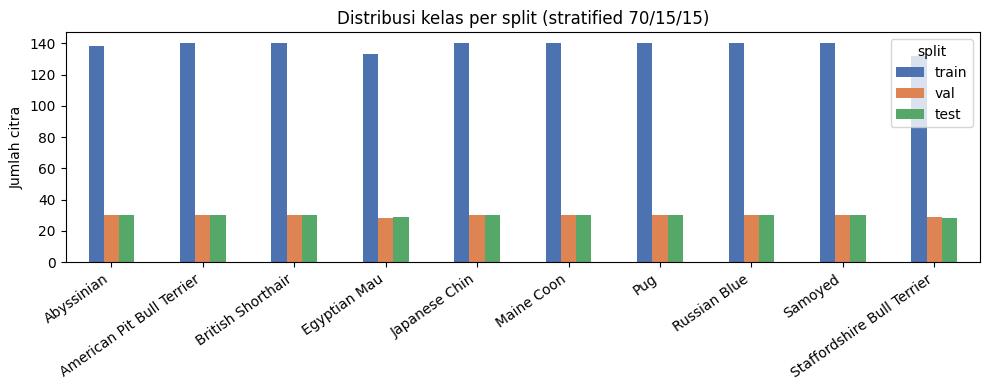

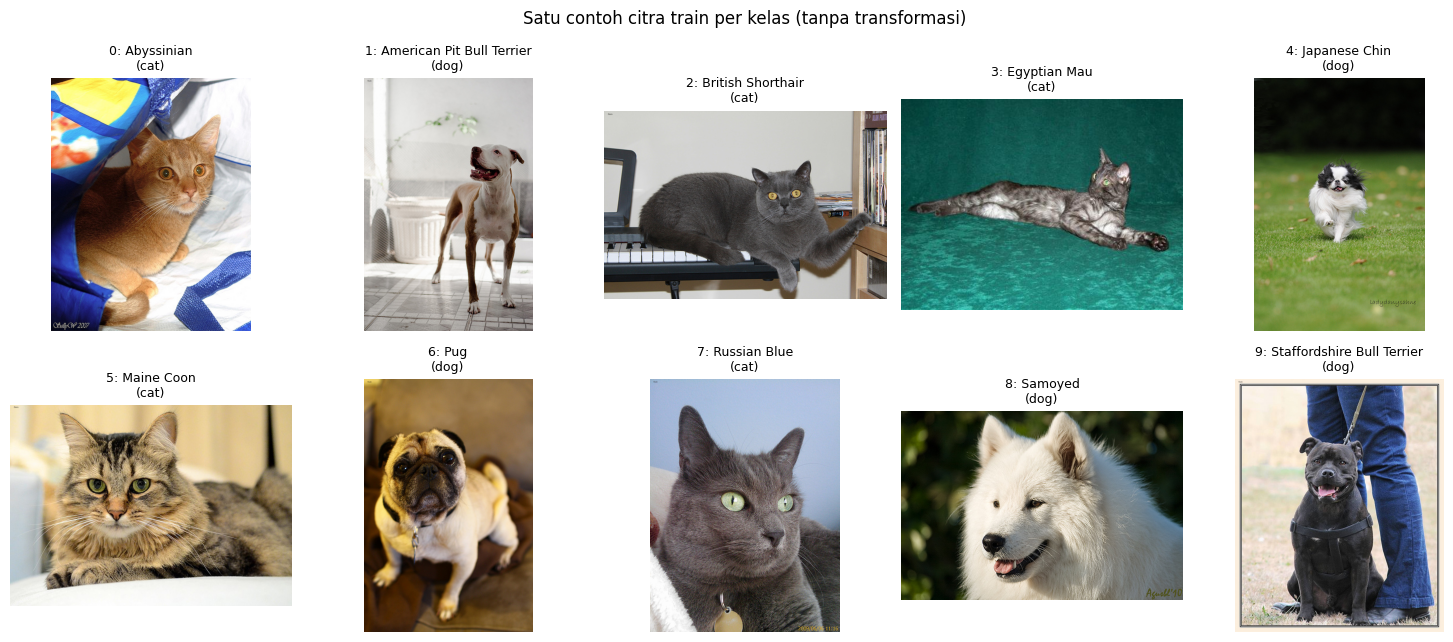

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
split_counts[["train", "val", "test"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Jumlah citra"); ax.set_xlabel("")
ax.set_title("Distribusi kelas per split (stratified 70/15/15)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for c, ax in enumerate(axes.ravel()):
    row = df[(df.split == "train") & (df.label == c)].iloc[0]
    ax.imshow(Image.open(row.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"{c}: {row.class_name}\n({row.species})", fontsize=9)
plt.suptitle("Satu contoh citra train per kelas (tanpa transformasi)")
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_images.png", dpi=120); plt.show()

## 7. Transformasi train dan evaluasi

* `eval_tf`: `Resize(256)` → `CenterCrop(224)` → `ToTensor` → `Normalize(ImageNet)`. Sel ini memastikan hasilnya identik secara numerik dengan `ResNet18_Weights.IMAGENET1K_V1.transforms()` yang dipakai di starter code.
* `train_tf_aug`: persis starter code PDF (Resize 256, RandomResizedCrop 224 scale 0.8–1.0, HorizontalFlip, Rotation 15°, ColorJitter brightness/contrast 0.2).
* `train_tf_noaug` (B4 skenario 1): sama dengan `eval_tf`, hanya resize/crop dan normalisasi.
* **Cache:** citra di-`Resize(256)` sekali lalu disimpan di RAM. Karena setiap pipeline diawali `Resize(256)` dan PIL tidak mengubah citra yang ukurannya sudah sama, hasilnya identik (diverifikasi di bawah); yang berkurang hanya biaya decode JPEG berulang.

In [8]:
MEAN, STD = CFG["imagenet_mean"], CFG["imagenet_std"]
_w = models.ResNet18_Weights.IMAGENET1K_V1
assert list(_w.transforms().mean) == MEAN and list(_w.transforms().std) == STD

eval_tf = transforms.Compose([
    transforms.Resize(CFG["resize"]),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf_aug = transforms.Compose([
    transforms.Resize(CFG["resize"]),
    transforms.RandomResizedCrop(CFG["img_size"], scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf_noaug = eval_tf
TRANSFORMS = {"aug": train_tf_aug, "noaug": train_tf_noaug}

# Verifikasi 1: eval_tf == weights.transforms()
_img = Image.open(df.path.iloc[0]).convert("RGB")
d1 = (eval_tf(_img) - _w.transforms()(_img)).abs().max().item()
print(f"max|eval_tf - weights.transforms()| = {d1:.2e}")
assert d1 < 1e-5

# --- Cache citra yang sudah di-Resize(256) -------------------------------------------
_resize = transforms.Resize(CFG["resize"])
if CFG["cache_images"]:
    t0 = time.time()
    IMAGES = [_resize(Image.open(p).convert("RGB")) for p in df.path]
    print(f"Cache {len(IMAGES)} citra selesai dalam {time.time() - t0:.1f} s")
    # Verifikasi 2: transformasi deterministik pada citra cache == pada citra asli
    d2 = (eval_tf(IMAGES[0]) - eval_tf(_img)).abs().max().item()
    print(f"max|eval_tf(cache) - eval_tf(asli)| = {d2:.2e}")
    assert d2 == 0.0
else:
    IMAGES = None

max|eval_tf - weights.transforms()| = 0.00e+00
Cache 1977 citra selesai dalam 9.0 s
max|eval_tf(cache) - eval_tf(asli)| = 0.00e+00


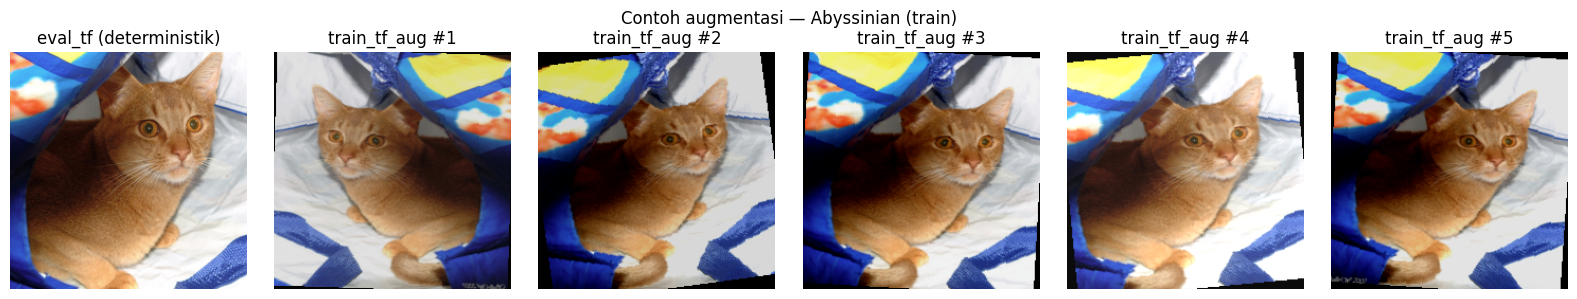

In [9]:
# Pratinjau augmentasi: memastikan augmentasi bekerja dan tetap mempertahankan identitas ras.
def denorm(t):
    t = t.clone() * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

_i = int(train_idx[0])
_src = IMAGES[_i] if IMAGES is not None else Image.open(df.path[_i]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(denorm(eval_tf(_src))); axes[0].set_title("eval_tf (deterministik)")
for k in range(1, 6):
    axes[k].imshow(denorm(train_tf_aug(_src))); axes[k].set_title(f"train_tf_aug #{k}")
for a in axes: a.axis("off")
plt.suptitle(f"Contoh augmentasi — {df.class_name[_i]} (train)")
plt.tight_layout(); plt.savefig(FIG_DIR / "augmentation_preview.png", dpi=120); plt.show()

## 8. Dataset dan DataLoader
Setiap split punya objek `Dataset` sendiri dengan transform sendiri. Tidak ada transform yang dipakai bersama antar split, sehingga augmentasi tidak bisa bocor ke val/test. `__getitem__` juga mengembalikan indeks baris, supaya prediksi dapat ditelusuri ke berkas citra aslinya.

In [10]:
PATHS, LABELS = df["path"].values, df["label"].values.astype(int)


class PetSubset(Dataset):
    def __init__(self, indices, transform):
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        i = int(self.indices[k])
        img = IMAGES[i] if IMAGES is not None else Image.open(PATHS[i]).convert("RGB")
        return self.transform(img), int(LABELS[i]), i


def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


def make_loaders(train_tf, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)   # urutan shuffle identik untuk setiap kondisi
    kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"],
              pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker)
    if CFG["num_workers"] > 0 and sys.platform.startswith("linux"):
        # Paksa 'fork': kelas Dataset yang didefinisikan di notebook tidak bisa di-pickle ke worker
        # 'spawn'/'forkserver' (default baru di Python 3.14). Worker tidak memakai CUDA, jadi fork aman.
        kw["multiprocessing_context"] = "fork"
    return {
        "train": DataLoader(PetSubset(train_idx, train_tf), shuffle=True, generator=g, drop_last=False, **kw),
        "train_clean": DataLoader(PetSubset(train_idx, eval_tf), shuffle=False, **kw),
        "val": DataLoader(PetSubset(val_idx, eval_tf), shuffle=False, **kw),
        "test": DataLoader(PetSubset(test_idx, eval_tf), shuffle=False, **kw),
    }


_l = make_loaders(train_tf_aug)
xb, yb, ib = next(iter(_l["train"]))
print("Batch train:", tuple(xb.shape), "| label:", yb[:8].tolist(), "| dtype:", xb.dtype)
assert xb.shape[1:] == (3, CFG["img_size"], CFG["img_size"])
assert _l["val"].dataset.transform is eval_tf and _l["test"].dataset.transform is eval_tf
assert set(_l["test"].dataset.indices) == S_te and set(_l["train"].dataset.indices) == S_tr
print({k: len(v.dataset) for k, v in _l.items()})
del _l

Batch train: (32, 3, 224, 224) | label: [3, 0, 0, 9, 1, 7, 8, 4] | dtype: torch.float32
{'train': 1383, 'train_clean': 1383, 'val': 297, 'test': 297}


## 9. Helper: model, strategi freeze/unfreeze, optimizer, training, evaluasi, early stopping

**Catatan penting: BatchNorm pada layer yang dibekukan.** `requires_grad=False` hanya menghentikan pembaruan bobot oleh gradien. Jika `model.train()` dipanggil, BatchNorm di backbone yang dibekukan **tetap memperbarui `running_mean`/`running_var`** dengan statistik data Pet. Akibatnya backbone B2 tidak lagi benar-benar beku. Karena itu, setiap epoch `set_train_mode` memasang `model.eval()` lalu hanya blok yang dilatih yang dikembalikan ke mode `train()`. Setelah training, kode memverifikasi bahwa **seluruh tensor di luar blok yang dilatih (termasuk buffer BN) tetap identik** dengan nilai awalnya.

In [11]:
# ---------------- Model ----------------
def build_model(arch: str, pretrained: bool):
    if SMOKE_TEST and pretrained:
        print("[SMOKE] bobot pretrained tidak diunduh; memakai inisialisasi acak.")
        pretrained = False
    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)            # 512 -> 10
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)   # 1280 -> 10 (Dropout 0.2 dipertahankan)
    else:
        raise ValueError(arch)
    return m


# ------------- Strategi: blok yang dilatih + LR per kelompok -------------
def trainable_groups(model, arch, strategy):
    # Kembalikan list (nama, prefix state_dict, modul, lr).
    if strategy == "scratch":
        return [("all", "", model, CFG["lr_scratch"])]
    if arch == "resnet18":
        if strategy == "feature_extraction":
            return [("fc", "fc", model.fc, CFG["lr_head"])]
        if strategy == "finetune_last":
            return [("layer4", "layer4", model.layer4, CFG["lr_backbone_ft"]),
                    ("fc", "fc", model.fc, CFG["lr_head"])]
    if arch == "efficientnet_b0":
        if strategy == "feature_extraction":
            return [("classifier", "classifier", model.classifier, CFG["lr_head"])]
        if strategy == "finetune_last":
            # Analog layer4: semua blok yang bekerja pada resolusi 7x7 (stage 6, 7, dan conv head 8).
            return [("features.6", "features.6", model.features[6], CFG["lr_backbone_ft"]),
                    ("features.7", "features.7", model.features[7], CFG["lr_backbone_ft"]),
                    ("features.8", "features.8", model.features[8], CFG["lr_backbone_ft"]),
                    ("classifier", "classifier", model.classifier, CFG["lr_head"])]
    raise ValueError((arch, strategy))


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total


def apply_freeze(model, groups):
    for p in model.parameters():
        p.requires_grad = False
    for _, _, mod, _ in groups:
        for p in mod.parameters():
            p.requires_grad = True


def build_optimizer(model, groups):
    param_groups, seen = [], set()
    for name, _, mod, lr in groups:
        ps = [p for p in mod.parameters() if p.requires_grad]
        for p in ps:
            assert id(p) not in seen, f"Parameter ganda di kelompok {name}"
            seen.add(id(p))
        param_groups.append({"params": ps, "lr": lr, "name": name})
    trainable_ids = {id(p) for p in model.parameters() if p.requires_grad}
    assert seen == trainable_ids, "Ada parameter trainable yang tidak masuk optimizer (atau sebaliknya)."
    return torch.optim.AdamW(param_groups, weight_decay=CFG["weight_decay"])


def set_train_mode(model, groups):
    # Blok beku -> eval (BN memakai running stats pretrained, dropout/stochastic depth nonaktif).
    model.eval()
    for _, _, mod, _ in groups:
        mod.train()


# ------------- Early stopping -------------
class EarlyStopping:
    def __init__(self, patience, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.best_epoch, self.counter = float("inf"), None, 0

    def step(self, val_loss, epoch):
        improved = val_loss < self.best - self.min_delta
        if improved:
            self.best, self.best_epoch, self.counter = val_loss, epoch, 0
        else:
            self.counter += 1
        return improved

    @property
    def should_stop(self):
        return self.counter >= self.patience


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


# ------------- Train / eval -------------
def train_one_epoch(model, loader, optimizer, criterion, groups):
    set_train_mode(model, groups)
    loss_sum, correct, n = 0.0, 0, 0
    for x, y, _ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    logits, ys, idxs = [], [], []
    for x, y, i in loader:
        logits.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y); idxs.append(i)
    logits, ys, idxs = torch.cat(logits), torch.cat(ys), torch.cat(idxs)
    loss = criterion(logits, ys).item()
    probs = logits.softmax(1).numpy()
    preds = probs.argmax(1)
    y_np = ys.numpy()
    return {
        "loss": loss,
        "acc": float((preds == y_np).mean()),
        "macro_f1": float(f1_score(y_np, preds, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        "y_true": y_np, "y_pred": preds, "probs": probs, "idx": idxs.numpy(),
    }


def frozen_state_snapshot(model, groups):
    prefixes = [p for _, p, _, _ in groups]
    if "" in prefixes:
        return {}
    keep = lambda k: not any(k == p or k.startswith(p + ".") for p in prefixes)
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if keep(k)}

In [12]:
# Uji unit kecil (tanpa training) untuk jumlah parameter ResNet-18 sesuai strategi.
EXPECTED_TRAINABLE_RESNET18 = {"scratch": 11_181_642, "feature_extraction": 5_130, "finetune_last": 8_398_858}
for strat, expected in EXPECTED_TRAINABLE_RESNET18.items():
    _m = build_model("resnet18", pretrained=False)
    _g = trainable_groups(_m, "resnet18", strat)
    apply_freeze(_m, _g)
    tr, tot = count_params(_m)
    _opt = build_optimizer(_m, _g)
    print(f"{strat:>20}: trainable={tr:>11,} / total={tot:,} | groups=" +
          ", ".join(f"{pg['name']}(lr={pg['lr']:g}, n={sum(p.numel() for p in pg['params']):,})" for pg in _opt.param_groups))
    assert tr == expected and tot == 11_181_642
del _m, _g, _opt

             scratch: trainable= 11,181,642 / total=11,181,642 | groups=all(lr=0.001, n=11,181,642)
  feature_extraction: trainable=      5,130 / total=11,181,642 | groups=fc(lr=0.001, n=5,130)
       finetune_last: trainable=  8,398,858 / total=11,181,642 | groups=layer4(lr=0.0001, n=8,393,728), fc(lr=0.001, n=5,130)


## 10. Fungsi eksperimen
`run_experiment` menjalankan satu kondisi dari awal: reseed, bangun DataLoader dan model, freeze, optimizer, lalu training dengan early stopping. Setelah itu checkpoint terbaik dipulihkan, val dievaluasi ulang, test dievaluasi sekali, dan semua log disimpan.

Definisi durasi: `duration_s` = waktu *training pass* + *validation pass* (sinkronisasi CUDA sebelum pengukuran). Evaluasi diagnostik train-tanpa-augmentasi dicatat terpisah (`time_train_clean_eval_s`) dan **tidak** dihitung sebagai durasi pelatihan.

In [13]:
RESULTS = {}


def run_experiment(code, arch, strategy, pretrained, aug, description):
    summ_path = RES_DIR / f"summary_{code}.json"
    ckpt_path = CKPT_DIR / f"{code}_best.pt"
    hist_path = RES_DIR / f"history_{code}.csv"
    pred_path = RES_DIR / f"test_predictions_{code}.csv"
    if CFG["resume"] and summ_path.exists() and ckpt_path.exists() and hist_path.exists():
        with open(summ_path) as f:
            s = json.load(f)
        if s.get("smoke_test") == SMOKE_TEST:
            print(f"[RESUME] {code} sudah selesai sebelumnya ({s['finished_at']}); memuat log tersimpan.")
            RESULTS[code] = s
            return s

    print("=" * 90); print(f"{code} | {description}"); print("=" * 90)
    if code in SIMULATE_FAIL:
        raise RuntimeError(f"[SMOKE] kegagalan disimulasikan untuk {code}")
    set_seed(SEED)
    loaders = make_loaders(TRANSFORMS[aug])
    model = build_model(arch, pretrained).to(DEVICE)
    groups = trainable_groups(model, arch, strategy)
    apply_freeze(model, groups)
    optimizer = build_optimizer(model, groups)
    criterion = nn.CrossEntropyLoss()
    trainable, total = count_params(model)
    if arch == "resnet18":
        assert trainable == EXPECTED_TRAINABLE_RESNET18[strategy], trainable
    lr_groups = {pg["name"]: pg["lr"] for pg in optimizer.param_groups}
    group_sizes = {pg["name"]: int(sum(p.numel() for p in pg["params"])) for pg in optimizer.param_groups}
    print(f"Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.3f}%)")
    print("LR per kelompok:", lr_groups, "| ukuran kelompok:", group_sizes)

    frozen0 = frozen_state_snapshot(model, groups)
    trained0 = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k not in frozen0}

    es = EarlyStopping(CFG["patience"], CFG["min_delta"])
    history, best_state = [], None
    t_train = t_val = t_clean = 0.0
    for epoch in range(1, CFG["max_epochs"] + 1):
        sync(); t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, loaders["train"], optimizer, criterion, groups)
        sync(); t1 = time.perf_counter()
        if CFG["eval_train_clean"]:
            trc = evaluate(model, loaders["train_clean"], criterion)
        sync(); t2 = time.perf_counter()
        va = evaluate(model, loaders["val"], criterion)
        sync(); t3 = time.perf_counter()
        t_train += t1 - t0; t_clean += t2 - t1; t_val += t3 - t2
        improved = es.step(va["loss"], epoch)
        if improved:
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        row = {"epoch": epoch,
               "train_loss": tr_loss, "train_acc": tr_acc,
               "train_clean_loss": trc["loss"] if CFG["eval_train_clean"] else np.nan,
               "train_clean_acc": trc["acc"] if CFG["eval_train_clean"] else np.nan,
               "val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": va["macro_f1"],
               "epoch_train_s": t1 - t0, "epoch_val_s": t3 - t2, "improved": improved}
        for name, lr in lr_groups.items():
            row[f"lr_{name}"] = lr
        history.append(row)
        print(f"ep {epoch:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | clean {row['train_clean_loss']:.4f}/{row['train_clean_acc']:.3f}"
              f" | val {va['loss']:.4f}/{va['acc']:.3f} | {t1-t0:5.1f}s {'*' if improved else ''}")
        if es.should_stop:
            print(f"Early stopping: val_loss tidak membaik selama {CFG['patience']} epoch.")
            break
    epochs_run = len(history)
    stopped_early = es.should_stop

    # ---- Pulihkan checkpoint terbaik (berdasarkan val loss) ----
    if best_state is None:
        raise RuntimeError(f"{code}: val_loss tidak pernah valid (NaN/inf?) — training divergen; periksa LR/data.")
    model.load_state_dict(best_state)
    torch.save(best_state, ckpt_path)

    # ---- Verifikasi freeze: semua tensor di luar blok trainable harus identik ----
    final_sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    if frozen0:
        changed = [k for k, v in frozen0.items() if not torch.equal(v, final_sd[k])]
        assert not changed, f"Tensor beku berubah: {changed[:5]}"
        print(f"Verifikasi freeze OK: {len(frozen0)} tensor beku (termasuk buffer BN) tidak berubah.")
    n_trained_changed = sum(not torch.equal(v, final_sd[k]) for k, v in trained0.items() if v.is_floating_point())
    assert n_trained_changed > 0, "Tidak ada bobot trainable yang berubah — training tidak berjalan?"

    # ---- Evaluasi pada checkpoint terpilih ----
    va = evaluate(model, loaders["val"], criterion)
    trc = evaluate(model, loaders["train_clean"], criterion)
    te = evaluate(model, loaders["test"], criterion)      # satu-satunya pemakaian test set untuk kondisi ini
    assert set(te["idx"].tolist()) == S_te
    best_row = history[es.best_epoch - 1]
    recheck_diff = abs(best_row["val_loss"] - va["loss"])
    if recheck_diff > 1e-3:   # selisih kecil wajar akibat nondeterminisme GPU; selisih besar = bug checkpoint
        raise RuntimeError(f"Checkpoint yang dipulihkan tidak sesuai epoch terbaik (selisih val_loss {recheck_diff:.2e}).")
    elif recheck_diff > 1e-5:
        warnings.warn(f"{code}: val_loss evaluasi ulang berbeda {recheck_diff:.2e} dari log epoch (nondeterminisme GPU).")

    per_class_f1 = f1_score(te["y_true"], te["y_pred"], average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
    cm = confusion_matrix(te["y_true"], te["y_pred"], labels=list(range(NUM_CLASSES)))

    pd.DataFrame(history).to_csv(hist_path, index=False)
    pred_df = pd.DataFrame({"row_idx": te["idx"], "image_id": df.image_id.values[te["idx"]],
                            "y_true": te["y_true"], "y_pred": te["y_pred"],
                            "confidence": te["probs"].max(1),
                            "prob_true": te["probs"][np.arange(len(te["y_true"])), te["y_true"]]})
    for c in range(NUM_CLASSES):
        pred_df[f"p_{c}"] = te["probs"][:, c]
    pred_df.to_csv(pred_path, index=False)

    s = {
        "code": code, "description": description, "arch": arch, "strategy": strategy,
        "pretrained": bool(pretrained and not SMOKE_TEST), "augmentation": aug, "seed": SEED,
        "trainable_params": int(trainable), "total_params": int(total),
        "lr_per_group": lr_groups, "params_per_group": group_sizes,
        "batch_size": CFG["batch_size"], "weight_decay": CFG["weight_decay"], "optimizer": "AdamW",
        "max_epochs": CFG["max_epochs"], "patience": CFG["patience"],
        "epochs_run": epochs_run, "best_epoch": int(es.best_epoch), "stopped_early": bool(stopped_early),
        "duration_s": t_train + t_val, "time_train_s": t_train, "time_val_s": t_val,
        "time_train_clean_eval_s": t_clean, "sec_per_epoch_train": t_train / epochs_run,
        "best_val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": va["macro_f1"],
        "train_clean_acc_at_best": trc["acc"], "train_clean_loss_at_best": trc["loss"],
        "train_aug_acc_at_best": best_row["train_acc"],
        "gap_acc_clean_train_minus_val": trc["acc"] - va["acc"],
        "gap_loss_val_minus_clean_train": va["loss"] - trc["loss"],
        "test_loss": te["loss"], "test_acc": te["acc"], "test_macro_f1": te["macro_f1"],
        "test_per_class_f1": {CLASS_NAMES[c]: float(per_class_f1[c]) for c in range(NUM_CLASSES)},
        "test_confusion_matrix": cm.tolist(),
        "test_evaluated_once": True,
        "val_loss_recheck_diff": float(recheck_diff),
        "smoke_test": SMOKE_TEST, "device": str(DEVICE), "gpu_name": ENV_INFO["gpu_name"],
        "finished_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    with open(summ_path, "w") as f:
        json.dump(s, f, indent=2)
    RESULTS[code] = s
    print(f"--> best_epoch={s['best_epoch']} | val_acc={s['val_acc']:.4f} | test_acc={s['test_acc']:.4f} "
          f"| test_macro_f1={s['test_macro_f1']:.4f} | durasi={s['duration_s']:.1f}s")
    del model, optimizer, best_state
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return s

## 11. B1 — Baseline from Scratch
ResNet-18 `weights=None`; seluruh 11,18 juta parameter dilatih dengan AdamW lr 1e-3.

In [14]:
_ = run_experiment("B1", "resnet18", "scratch", pretrained=False, aug="aug",
               description="ResNet-18 from scratch (weights=None), semua parameter dilatih")

B1 | ResNet-18 from scratch (weights=None), semua parameter dilatih
Trainable params: 11,181,642 / 11,181,642 (100.000%)
LR per kelompok: {'all': 0.001} | ukuran kelompok: {'all': 11181642}
ep 01 | train 2.3696/0.167 | clean 2.2535/0.205 | val 2.2997/0.222 |   7.8s *
ep 02 | train 2.1224/0.258 | clean 2.5558/0.218 | val 2.5565/0.212 |   7.1s 
ep 03 | train 1.9423/0.319 | clean 2.0584/0.333 | val 2.1239/0.320 |   8.1s *
ep 04 | train 1.8947/0.312 | clean 2.0150/0.286 | val 2.0485/0.273 |   7.2s *
ep 05 | train 1.8455/0.358 | clean 1.8593/0.358 | val 1.9141/0.354 |   6.4s *
ep 06 | train 1.7285/0.396 | clean 1.8460/0.334 | val 1.9015/0.296 |   8.4s *
ep 07 | train 1.7358/0.392 | clean 1.5724/0.441 | val 1.6252/0.421 |  12.0s *
ep 08 | train 1.5872/0.438 | clean 1.8366/0.396 | val 1.8616/0.377 |   8.2s 
ep 09 | train 1.5745/0.441 | clean 1.8364/0.355 | val 1.8095/0.357 |   6.4s 
ep 10 | train 1.5295/0.463 | clean 1.4199/0.511 | val 1.5847/0.451 |   6.5s *
ep 11 | train 1.4010/0.509 | clea

## 12. B2 — Feature Extraction
Backbone `IMAGENET1K_V1` dibekukan (termasuk statistik BN); hanya `fc = nn.Linear(512, 10)` dilatih (5.130 parameter).

In [15]:
_ = run_experiment("B2", "resnet18", "feature_extraction", pretrained=True, aug="aug",
               description="ResNet-18 pretrained, backbone beku, hanya fc dilatih")

B2 | ResNet-18 pretrained, backbone beku, hanya fc dilatih
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]

Trainable params: 5,130 / 11,181,642 (0.046%)
LR per kelompok: {'fc': 0.001} | ukuran kelompok: {'fc': 5130}


ep 01 | train 1.3405/0.608 | clean 0.6820/0.839 | val 0.6497/0.842 |   7.9s *
ep 02 | train 0.5746/0.852 | clean 0.4378/0.892 | val 0.4190/0.889 |   5.5s *
ep 03 | train 0.4159/0.894 | clean 0.3593/0.901 | val 0.3430/0.892 |   6.1s *
ep 04 | train 0.3407/0.917 | clean 0.2898/0.919 | val 0.2848/0.919 |   7.1s *
ep 05 | train 0.3074/0.911 | clean 0.2703/0.918 | val 0.2658/0.916 |   5.6s *
ep 06 | train 0.2720/0.926 | clean 0.2391/0.931 | val 0.2414/0.923 |   6.9s *
ep 07 | train 0.2451/0.928 | clean 0.2261/0.932 | val 0.2305/0.923 |   6.5s *
ep 08 | train 0.2233/0.938 | clean 0.2286/0.927 | val 0.2320/0.929 |   5.4s 
ep 09 | train 0.2175/0.938 | clean 0.2121/0.935 | val 0.2175/0.923 |   7.2s *
ep 10 | train 0.2014/0.939 | clean 0.1910/0.936 | val 0.2073/0.909 |   5.3s *
ep 11 | train 0.1828/0.959 | clean 0.1993/0.930 | val 0.2171/0.926 |   6.0s 
ep 12 | train 0.1860/0.947 | clean 0.2113/0.926 | val 0.2253/0.919 |   7.4s 
ep 13 | train 0.1788/0.948 | clean 0.1866/0.931 | val 0.1991/0.923 

## 13. B3 — Progressive Fine-Tuning
`layer4` + `fc` dibuka; LR diferensial `layer4` = 1e-4, `fc` = 1e-3; AdamW `weight_decay=1e-2`. Layer `conv1`–`layer3` tetap beku. BN di `layer4` dalam mode train, BN di bagian beku dalam mode eval.

In [16]:
_ = run_experiment("B3", "resnet18", "finetune_last", pretrained=True, aug="aug",
               description="ResNet-18 pretrained, unfreeze layer4+fc, LR 1e-4/1e-3")

B3 | ResNet-18 pretrained, unfreeze layer4+fc, LR 1e-4/1e-3
Trainable params: 8,398,858 / 11,181,642 (75.113%)
LR per kelompok: {'layer4': 0.0001, 'fc': 0.001} | ukuran kelompok: {'layer4': 8393728, 'fc': 5130}
ep 01 | train 0.7871/0.766 | clean 0.1821/0.931 | val 0.2186/0.909 |   5.5s *
ep 02 | train 0.2180/0.927 | clean 0.1137/0.965 | val 0.1960/0.923 |   7.3s *
ep 03 | train 0.1270/0.967 | clean 0.0778/0.978 | val 0.1744/0.943 |   5.8s *
ep 04 | train 0.0815/0.978 | clean 0.0528/0.985 | val 0.1780/0.933 |   5.4s 
ep 05 | train 0.0599/0.986 | clean 0.0388/0.987 | val 0.1945/0.933 |   7.4s 
ep 06 | train 0.0391/0.994 | clean 0.0254/0.993 | val 0.1827/0.926 |   5.5s 
ep 07 | train 0.0418/0.988 | clean 0.0554/0.979 | val 0.2641/0.923 |   6.0s 
ep 08 | train 0.0297/0.993 | clean 0.0182/0.996 | val 0.1749/0.939 |   7.0s 
Early stopping: val_loss tidak membaik selama 5 epoch.
Verifikasi freeze OK: 90 tensor beku (termasuk buffer BN) tidak berubah.
--> best_epoch=3 | val_acc=0.9428 | test_a

## 14. B4 — Uji kontrol data augmentation (basis: B3)
Dua skenario dijalankan dengan split, seed, inisialisasi head, urutan shuffle, dan hyperparameter yang **identik**. Satu-satunya perbedaan adalah transform pada train set. Model diinisialisasi ulang di awal tiap skenario (`set_seed(42)` dipanggil lagi).

* `B4_noaug`: train memakai `Resize(256) → CenterCrop(224) → Normalize`.
* `B4_aug`: train memakai augmentasi starter code. Konfigurasinya identik dengan B3 dan sengaja dijalankan ulang; selisih B4_aug vs B3 menunjukkan besarnya nondeterminisme GPU antar-run.

In [17]:
_ = run_experiment("B4_noaug", "resnet18", "finetune_last", pretrained=True, aug="noaug",
               description="B3 tanpa augmentasi (Resize/CenterCrop + Normalize)")
_ = run_experiment("B4_aug", "resnet18", "finetune_last", pretrained=True, aug="aug",
               description="B3 dengan augmentasi (Flip, Rotation 15, ColorJitter)")
_b3, _b4a = RESULTS["B3"], RESULTS["B4_aug"]
print(f"Reproduksibilitas B3 vs B4_aug (konfigurasi identik): "
      f"|dval_acc|={abs(_b3['val_acc']-_b4a['val_acc']):.4f}, |dtest_f1|={abs(_b3['test_macro_f1']-_b4a['test_macro_f1']):.4f}, "
      f"best_epoch {_b3['best_epoch']} vs {_b4a['best_epoch']}")

B4_noaug | B3 tanpa augmentasi (Resize/CenterCrop + Normalize)
Trainable params: 8,398,858 / 11,181,642 (75.113%)
LR per kelompok: {'layer4': 0.0001, 'fc': 0.001} | ukuran kelompok: {'layer4': 8393728, 'fc': 5130}
ep 01 | train 0.7038/0.802 | clean 0.1143/0.966 | val 0.2268/0.912 |   2.3s *
ep 02 | train 0.1134/0.970 | clean 0.0272/0.998 | val 0.1778/0.933 |   3.5s *
ep 03 | train 0.0354/0.999 | clean 0.0105/1.000 | val 0.1616/0.946 |   2.3s *
ep 04 | train 0.0169/0.999 | clean 0.0040/1.000 | val 0.1582/0.943 |   2.4s *
ep 05 | train 0.0101/0.999 | clean 0.0022/1.000 | val 0.1650/0.936 |   2.3s 
ep 06 | train 0.0098/0.999 | clean 0.0017/1.000 | val 0.1580/0.936 |   2.3s *
ep 07 | train 0.0096/0.999 | clean 0.0014/1.000 | val 0.1731/0.939 |   3.3s 
ep 08 | train 0.0051/1.000 | clean 0.0010/1.000 | val 0.1554/0.960 |   2.3s *
ep 09 | train 0.0033/1.000 | clean 0.0006/1.000 | val 0.1599/0.943 |   2.3s 
ep 10 | train 0.0020/1.000 | clean 0.0004/1.000 | val 0.1657/0.939 |   2.5s 
ep 11 | tr

## 15. B5 (bonus) — EfficientNet-B0 dengan konfigurasi terbaik
Konfigurasi terbaik dipilih **otomatis dari metrik validation** (val accuracy pada checkpoint; seri → val loss) di antara kondisi pretrained ResNet-18 (B2, B3, B4_noaug, B4_aug). Strategi itu lalu diterapkan pada EfficientNet-B0 `IMAGENET1K_V1`:

* `feature_extraction` → hanya `classifier` (Dropout 0.2 + Linear 1280→10) yang dilatih.
* `finetune_last` → `features[6]`, `features[7]`, `features[8]` + `classifier`. Ini analog `layer4`, karena ketiganya adalah blok yang bekerja pada resolusi 7×7, seperti `layer4` di ResNet-18.

Transform dibuat sama dengan ResNet-18 (Resize 256 bilinear → 224) agar perbandingan adil. Transform bawaan EfficientNet-B0 di torchvision memakai interpolasi bicubic, jadi ini penyesuaian yang disengaja dan didokumentasikan.

In [18]:
def pick_best(codes):
    cand = [RESULTS[c] for c in codes if c in RESULTS]
    return sorted(cand, key=lambda s: (-s["val_acc"], s["best_val_loss"]))[0]

# B5 adalah bonus: kegagalan apa pun di sini dicatat lalu dilewati agar sel wajib setelahnya tetap berjalan.
B5_STATUS = {"run": CFG["run_b5"], "ok": False, "error": None}
if CFG["run_b5"]:
    try:
        best_rn = pick_best(["B2", "B3", "B4_noaug", "B4_aug"])
        print(f"Konfigurasi terbaik (validation): {best_rn['code']} -> strategy={best_rn['strategy']}, aug={best_rn['augmentation']}"
              f" (val_acc={best_rn['val_acc']:.4f}, val_loss={best_rn['best_val_loss']:.4f})")
        B5_STATUS["source_condition"] = best_rn["code"]
        _ = run_experiment("B5", "efficientnet_b0", best_rn["strategy"], pretrained=True, aug=best_rn["augmentation"],
                           description=f"EfficientNet-B0, strategi {best_rn['strategy']} + aug={best_rn['augmentation']} (dari {best_rn['code']})")
        B5_STATUS["ok"] = True
    except Exception as e:
        B5_STATUS["error"] = f"{type(e).__name__}: {e}"
        RESULTS.pop("B5", None)
        warnings.warn(f"B5 gagal dan DILEWATI (B1-B4 tidak terpengaruh): {B5_STATUS['error']}")
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
else:
    print("B5 dilewati (CFG['run_b5']=False).")
with open(RES_DIR / "b5_status.json", "w") as f:
    json.dump(B5_STATUS, f, indent=2)
print("Status B5:", B5_STATUS)

Konfigurasi terbaik (validation): B4_noaug -> strategy=finetune_last, aug=noaug (val_acc=0.9596, val_loss=0.1554)
B5 | EfficientNet-B0, strategi finetune_last + aug=noaug (dari B4_noaug)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 175MB/s]


Trainable params: 3,168,550 / 4,020,358 (78.813%)
LR per kelompok: {'features.6': 0.0001, 'features.7': 0.0001, 'features.8': 0.0001, 'classifier': 0.001} | ukuran kelompok: {'features.6': 2026348, 'features.7': 717232, 'features.8': 412160, 'classifier': 12810}
ep 01 | train 1.0134/0.763 | clean 0.2020/0.949 | val 0.2328/0.933 |   3.5s *
ep 02 | train 0.2085/0.942 | clean 0.0742/0.991 | val 0.1409/0.960 |   4.1s *
ep 03 | train 0.1095/0.973 | clean 0.0315/0.999 | val 0.1184/0.963 |   3.3s *
ep 04 | train 0.0600/0.990 | clean 0.0119/1.000 | val 0.1045/0.963 |   4.0s *
ep 05 | train 0.0367/0.995 | clean 0.0051/1.000 | val 0.1032/0.963 |   3.3s *
ep 06 | train 0.0263/0.995 | clean 0.0032/1.000 | val 0.1079/0.963 |   3.8s 
ep 07 | train 0.0193/0.997 | clean 0.0019/1.000 | val 0.1127/0.963 |   3.3s 
ep 08 | train 0.0174/0.998 | clean 0.0018/1.000 | val 0.1350/0.960 |   3.7s 
ep 09 | train 0.0165/0.995 | clean 0.0010/1.000 | val 0.1228/0.960 |   3.3s 
ep 10 | train 0.0135/0.999 | clean 0.00

## 16. Tabel konsolidasi (C1)
Tabel di bawah dibangkitkan langsung dari `results/summary_*.json` dan diekspor ke `summary.csv` / `summary.json` / `summary_table.md`. Salin tabel markdown itu ke laporan, jangan diketik ulang.

Kolom tambahan `Test Macro F1 CI95` adalah interval bootstrap 95% (2.000 resample test set, seed 42). Ini hanya menggambarkan ketidakpastian akibat ukuran test set yang kecil, **bukan** variasi antar-seed.

In [19]:
ORDER = [c for c in ["B1", "B2", "B3", "B4_noaug", "B4_aug", "B5"] if c in RESULTS]
PREDS = {c: pd.read_csv(RES_DIR / f"test_predictions_{c}.csv") for c in ORDER}
for c in ORDER:   # semua kondisi harus dievaluasi pada test set yang sama, dengan urutan yang sama
    assert (PREDS[c].row_idx.values == PREDS[ORDER[0]].row_idx.values).all()
    assert abs(f1_score(PREDS[c].y_true, PREDS[c].y_pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0) - RESULTS[c]["test_macro_f1"]) < 1e-9

rng_bs = np.random.default_rng(SEED)
N_TEST = len(PREDS[ORDER[0]])
BOOT_IDX = rng_bs.integers(0, N_TEST, size=(2000, N_TEST))   # resample yang sama untuk semua kondisi (paired)

def boot_f1(c):
    yt, yp = PREDS[c].y_true.values, PREDS[c].y_pred.values
    return np.array([f1_score(yt[b], yp[b], average="macro", labels=list(range(NUM_CLASSES)), zero_division=0) for b in BOOT_IDX])

BOOT = {c: boot_f1(c) for c in ORDER}

rows = []
for c in ORDER:
    s = RESULTS[c]
    lo, hi = np.percentile(BOOT[c], [2.5, 97.5])
    rows.append({
        "Kode": c, "Arsitektur": s["arch"], "Strategi": s["strategy"], "Augmentasi": s["augmentation"],
        "Pretrained": s["pretrained"], "Trainable params": s["trainable_params"], "Total params": s["total_params"],
        "Learning rate": ", ".join(f"{k}={v:g}" for k, v in s["lr_per_group"].items()),
        "Epoch dijalankan": s["epochs_run"], "Epoch konvergen (best)": s["best_epoch"],
        "Early stop?": s["stopped_early"], "Durasi (s)": round(s["duration_s"], 1),
        "s/epoch (train)": round(s["sec_per_epoch_train"], 2),
        "Val loss (best)": round(s["best_val_loss"], 4), "Val acc": round(s["val_acc"], 4),
        "Train acc clean": round(s["train_clean_acc_at_best"], 4),
        "Gap acc (train-val)": round(s["gap_acc_clean_train_minus_val"], 4),
        "Test acc": round(s["test_acc"], 4), "Test Macro F1": round(s["test_macro_f1"], 4),
        "Test Macro F1 CI95": f"[{lo:.3f}, {hi:.3f}]",
    })
summary_df = pd.DataFrame(rows)
summary_df.to_csv(RES_DIR / "summary.csv", index=False)
with open(RES_DIR / "summary.json", "w") as f:
    json.dump({c: RESULTS[c] for c in ORDER}, f, indent=2)

c1_cols = ["Kode", "Strategi", "Augmentasi", "Trainable params", "Learning rate", "Epoch konvergen (best)",
           "Epoch dijalankan", "Durasi (s)", "Val acc", "Test Macro F1", "Test Macro F1 CI95"]
try:
    table_md = summary_df[c1_cols].to_markdown(index=False)          # butuh paket 'tabulate'
except ImportError:
    table_md = "| " + " | ".join(c1_cols) + " |\n|" + "---|" * len(c1_cols) + "\n" + "\n".join(
        "| " + " | ".join(str(v) for v in r) + " |" for r in summary_df[c1_cols].values)
with open(RES_DIR / "summary_table.md", "w") as f:
    f.write(table_md)
summary_df

,Kode,Arsitektur,Strategi,Augmentasi,Pretrained,Trainable params,Total params,Learning rate,Epoch dijalankan,Epoch konvergen (best),Early stop?,Durasi (s),s/epoch (train),Val loss (best),Val acc,Train acc clean,Gap acc (train-val),Test acc,Test Macro F1,Test Macro F1 CI95
0,B1,resnet18,scratch,aug,False,11181642,11181642,all=0.001,20,15,True,168.5,7.66,1.3495,0.5320,0.5871,0.0551,0.5017,0.4957,"[0.438, 0.546]"
1,B2,resnet18,feature_extraction,aug,True,5130,11181642,fc=0.001,27,22,True,188.8,6.29,0.1713,0.9428,0.9516,0.0088,0.9259,0.9254,"[0.894, 0.952]"
2,B3,resnet18,finetune_last,aug,True,8398858,11181642,"layer4=0.0001, fc=0.001",8,3,True,55.2,6.22,0.1744,0.9428,0.9783,0.0355,0.9394,0.9385,"[0.909, 0.964]"
3,B4_noaug,resnet18,finetune_last,noaug,True,8398858,11181642,"layer4=0.0001, fc=0.001",13,8,True,42.6,2.59,0.1554,0.9596,1.0000,0.0404,0.9562,0.9552,"[0.930, 0.976]"
4,B4_aug,resnet18,finetune_last,aug,True,8398858,11181642,"layer4=0.0001, fc=0.001",8,3,True,55.6,6.30,0.1744,0.9428,0.9783,0.0355,0.9394,0.9385,"[0.909, 0.964]"
5,B5,efficientnet_b0,finetune_last,noaug,True,3168550,4020358,"features.6=0.0001, features.7=0.0001, features...",10,5,True,43.0,3.58,0.1032,0.9630,1.0000,0.0370,0.9764,0.9762,"[0.957, 0.992]"


In [20]:
# Selisih berpasangan (paired bootstrap) untuk perbandingan kunci. Interval yang memuat 0
# berarti selisih tersebut TIDAK dapat dibedakan dari noise ukuran test set (single seed).
PAIRS = [("B2", "B1"), ("B3", "B1"), ("B3", "B2"), ("B4_aug", "B4_noaug"), ("B4_aug", "B3")]
if "B5" in ORDER:
    PAIRS.append(("B5", pick_best(["B2", "B3", "B4_noaug", "B4_aug"])["code"]))
diff_rows = []
for a, b in PAIRS:
    d = BOOT[a] - BOOT[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    diff_rows.append({"A": a, "B": b, "F1(A)-F1(B) titik": RESULTS[a]["test_macro_f1"] - RESULTS[b]["test_macro_f1"],
                      "CI95 bawah": lo, "CI95 atas": hi, "CI memuat 0?": bool(lo <= 0 <= hi)})
diff_df = pd.DataFrame(diff_rows)
diff_df.to_csv(RES_DIR / "paired_bootstrap_f1_diff.csv", index=False)
diff_df

,A,B,F1(A)-F1(B) titik,CI95 bawah,CI95 atas,CI memuat 0?
0,B2,B1,0.429696,0.374003,0.489959,False
1,B3,B1,0.442856,0.389902,0.500766,False
2,B3,B2,0.013160,-0.011400,0.040865,True
3,B4_aug,B4_noaug,-0.016664,-0.041202,0.007097,True
4,B4_aug,B3,0.000000,0.000000,0.000000,True
5,B5,B4_noaug,0.020982,0.000279,0.044416,False


## 17. Kurva training loss vs validation loss (B1, B2, B3)
Garis putus-putus menunjukkan *train loss* yang dievaluasi ulang tanpa augmentasi (mode eval). Train loss biasa dihitung saat training berlangsung dengan augmentasi aktif, sehingga nilainya cenderung lebih tinggi. Garis vertikal menandai epoch checkpoint (val loss terendah).

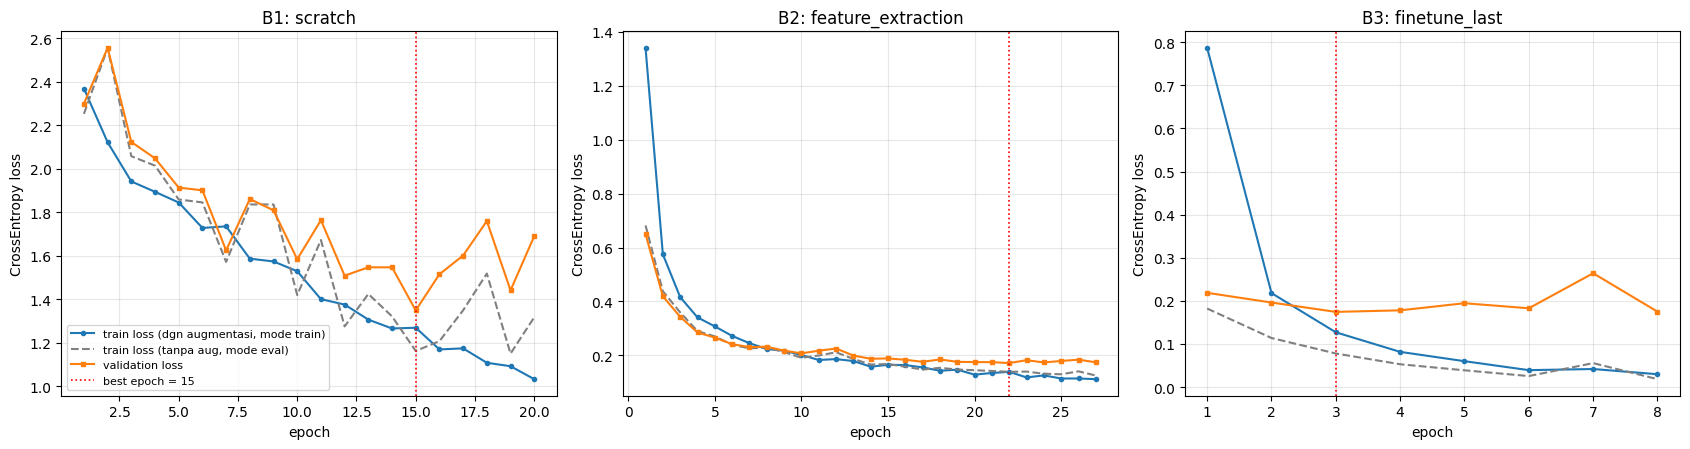

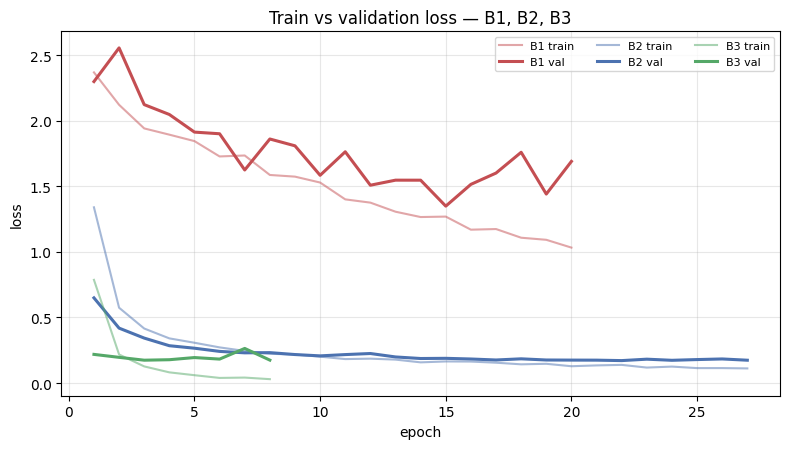

In [21]:
HIST = {c: pd.read_csv(RES_DIR / f"history_{c}.csv") for c in ORDER}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=False)
for ax, c in zip(axes, ["B1", "B2", "B3"]):
    h = HIST[c]
    ax.plot(h.epoch, h.train_loss, "o-", ms=3, label="train loss (dgn augmentasi, mode train)")
    ax.plot(h.epoch, h.train_clean_loss, "--", color="gray", label="train loss (tanpa aug, mode eval)")
    ax.plot(h.epoch, h.val_loss, "s-", ms=3, label="validation loss")
    ax.axvline(RESULTS[c]["best_epoch"], color="red", ls=":", lw=1.2, label=f"best epoch = {RESULTS[c]['best_epoch']}")
    ax.set_title(f"{c}: {RESULTS[c]['strategy']}"); ax.set_xlabel("epoch"); ax.set_ylabel("CrossEntropy loss")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "loss_curves_B1_B2_B3.png", dpi=150); plt.show()

# Versi overlay (satu sumbu) untuk perbandingan langsung
fig, ax = plt.subplots(figsize=(8, 4.6))
for c, col in zip(["B1", "B2", "B3"], ["#C44E52", "#4C72B0", "#55A868"]):
    h = HIST[c]
    ax.plot(h.epoch, h.train_loss, "-", color=col, alpha=0.5, label=f"{c} train")
    ax.plot(h.epoch, h.val_loss, "-", color=col, lw=2.2, label=f"{c} val")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Train vs validation loss — B1, B2, B3"); ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "loss_overlay_B1_B2_B3.png", dpi=150); plt.show()

## 18. Perbandingan metrik dan generalization gap (B4)
*Generalization gap* didefinisikan sebagai `train_clean_acc − val_acc`, di mana *train_clean* adalah train set yang dievaluasi tanpa augmentasi dalam mode eval. Dengan definisi ini, gap B4_noaug dan B4_aug dapat dibandingkan secara adil; gap yang dihitung dari akurasi train ber-augmentasi akan tampak mengecil secara artifisial.

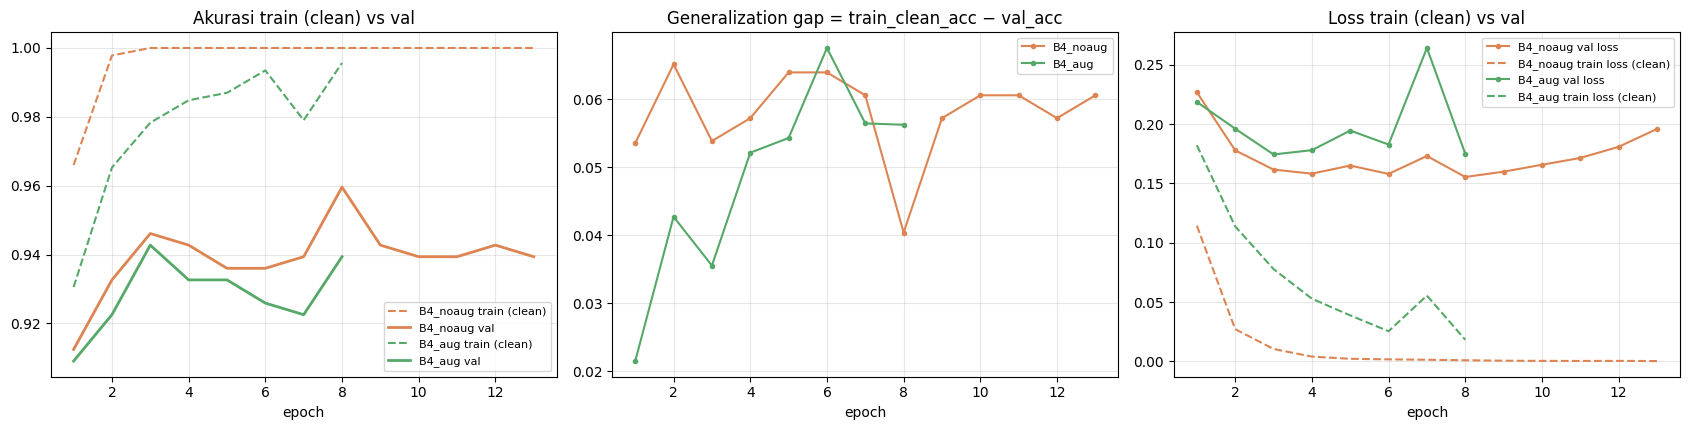

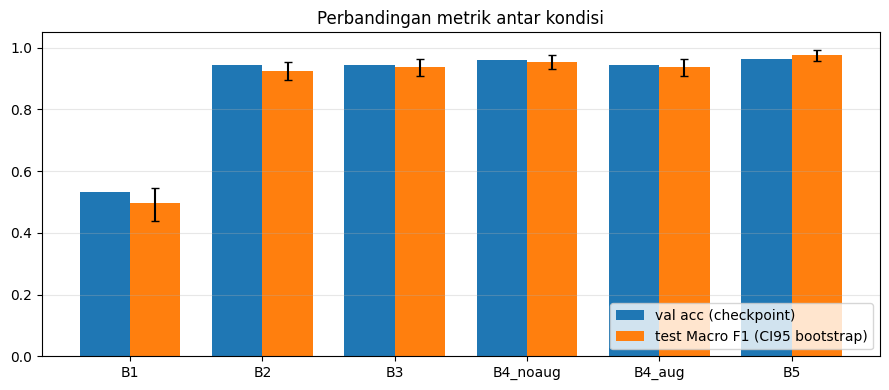

,Kode,Train acc clean,Val acc,Gap acc (train-val),Val loss (best),Test Macro F1
0,B1,0.5871,0.5320,0.0551,1.3495,0.4957
1,B2,0.9516,0.9428,0.0088,0.1713,0.9254
2,B3,0.9783,0.9428,0.0355,0.1744,0.9385
3,B4_noaug,1.0000,0.9596,0.0404,0.1554,0.9552
4,B4_aug,0.9783,0.9428,0.0355,0.1744,0.9385
5,B5,1.0000,0.9630,0.0370,0.1032,0.9762


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for c, col in zip(["B4_noaug", "B4_aug"], ["#DD8452", "#55A868"]):
    h = HIST[c]
    axes[0].plot(h.epoch, h.train_clean_acc, "--", color=col, label=f"{c} train (clean)")
    axes[0].plot(h.epoch, h.val_acc, "-", color=col, lw=2, label=f"{c} val")
    axes[1].plot(h.epoch, h.train_clean_acc - h.val_acc, "-o", ms=3, color=col, label=c)
    axes[2].plot(h.epoch, h.val_loss, "-o", ms=3, color=col, label=f"{c} val loss")
    axes[2].plot(h.epoch, h.train_clean_loss, "--", color=col, label=f"{c} train loss (clean)")
axes[0].set_title("Akurasi train (clean) vs val"); axes[1].set_title("Generalization gap = train_clean_acc − val_acc")
axes[2].set_title("Loss train (clean) vs val")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "B4_augmentation_gap.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ORDER)); w = 0.38
ci = np.array([np.percentile(BOOT[c], [2.5, 97.5]) for c in ORDER])
f1s = np.array([RESULTS[c]["test_macro_f1"] for c in ORDER])
ax.bar(x - w/2, [RESULTS[c]["val_acc"] for c in ORDER], w, label="val acc (checkpoint)")
ax.bar(x + w/2, f1s, w, yerr=[f1s - ci[:, 0], ci[:, 1] - f1s], capsize=3, label="test Macro F1 (CI95 bootstrap)")
ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3); ax.legend(loc="lower right")
ax.set_title("Perbandingan metrik antar kondisi")
plt.tight_layout(); plt.savefig(FIG_DIR / "metrics_comparison.png", dpi=150); plt.show()
summary_df[["Kode", "Train acc clean", "Val acc", "Gap acc (train-val)", "Val loss (best)", "Test Macro F1"]]

## 19. Confusion matrix — model terbaik (dipilih berdasarkan validation)

Model terbaik berdasarkan validation: B5 (val_acc=0.9630, val_loss=0.1032)
Catatan: pemilihan ini TIDAK memakai metrik test.


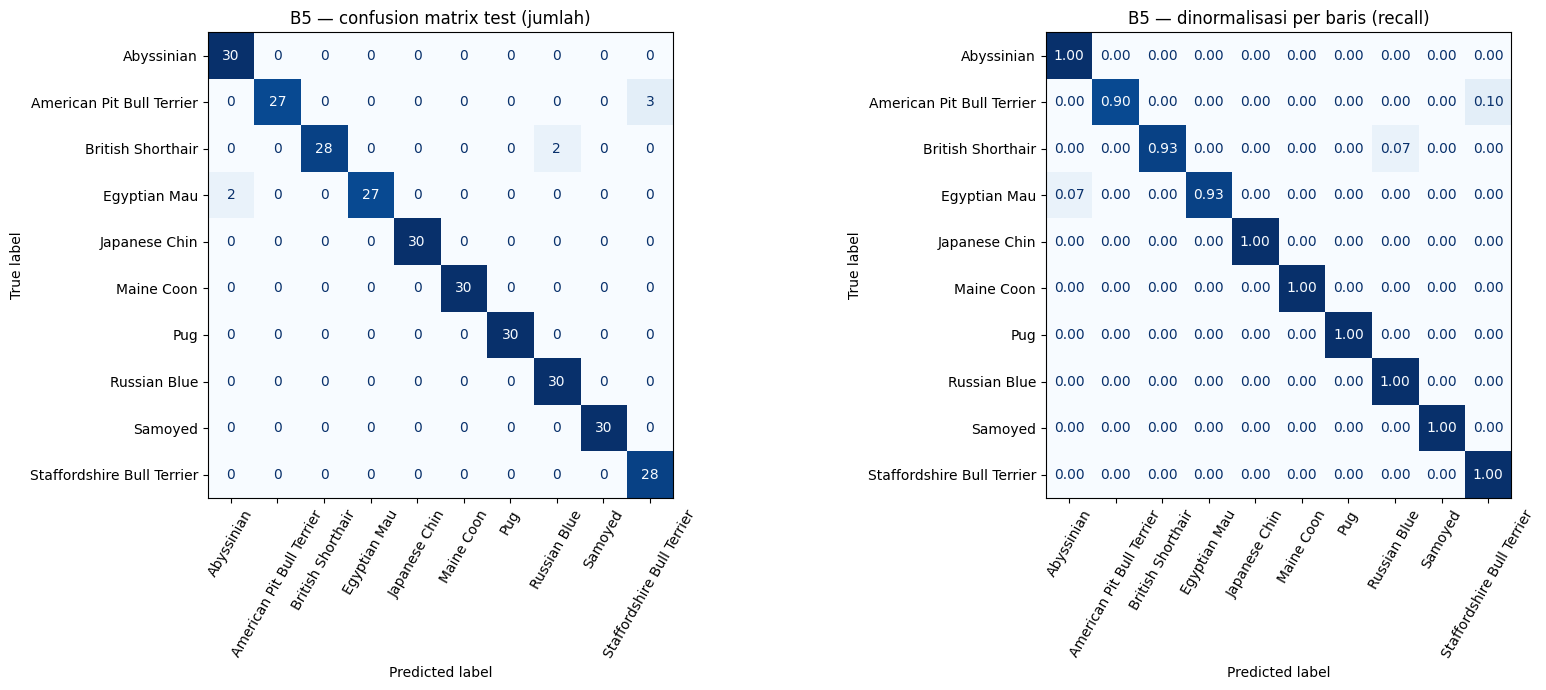

,true,pred,count
0,American Pit Bull Terrier,Staffordshire Bull Terrier,3
1,British Shorthair,Russian Blue,2
2,Egyptian Mau,Abyssinian,2


In [23]:
BEST = pick_best(ORDER)
BEST_CODE = BEST["code"]
print(f"Model terbaik berdasarkan validation: {BEST_CODE} (val_acc={BEST['val_acc']:.4f}, val_loss={BEST['best_val_loss']:.4f})")
print("Catatan: pemilihan ini TIDAK memakai metrik test.")
with open(RES_DIR / "best_model.json", "w") as f:
    json.dump({"best_code": BEST_CODE, "rule": CFG["best_condition_rule"],
               "val_acc": BEST["val_acc"], "best_val_loss": BEST["best_val_loss"]}, f, indent=2)

cm = np.array(BEST["test_confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=axes[0], xticks_rotation=60, colorbar=False, cmap="Blues")
axes[0].set_title(f"{BEST_CODE} — confusion matrix test (jumlah)")
cmn = cm / cm.sum(1, keepdims=True)
ConfusionMatrixDisplay(cmn, display_labels=CLASS_NAMES).plot(ax=axes[1], xticks_rotation=60, colorbar=False, cmap="Blues", values_format=".2f")
axes[1].set_title(f"{BEST_CODE} — dinormalisasi per baris (recall)")
plt.tight_layout(); plt.savefig(FIG_DIR / f"confusion_matrix_{BEST_CODE}.png", dpi=150); plt.show()

off = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=["true", "pred", "count"]).head(10)

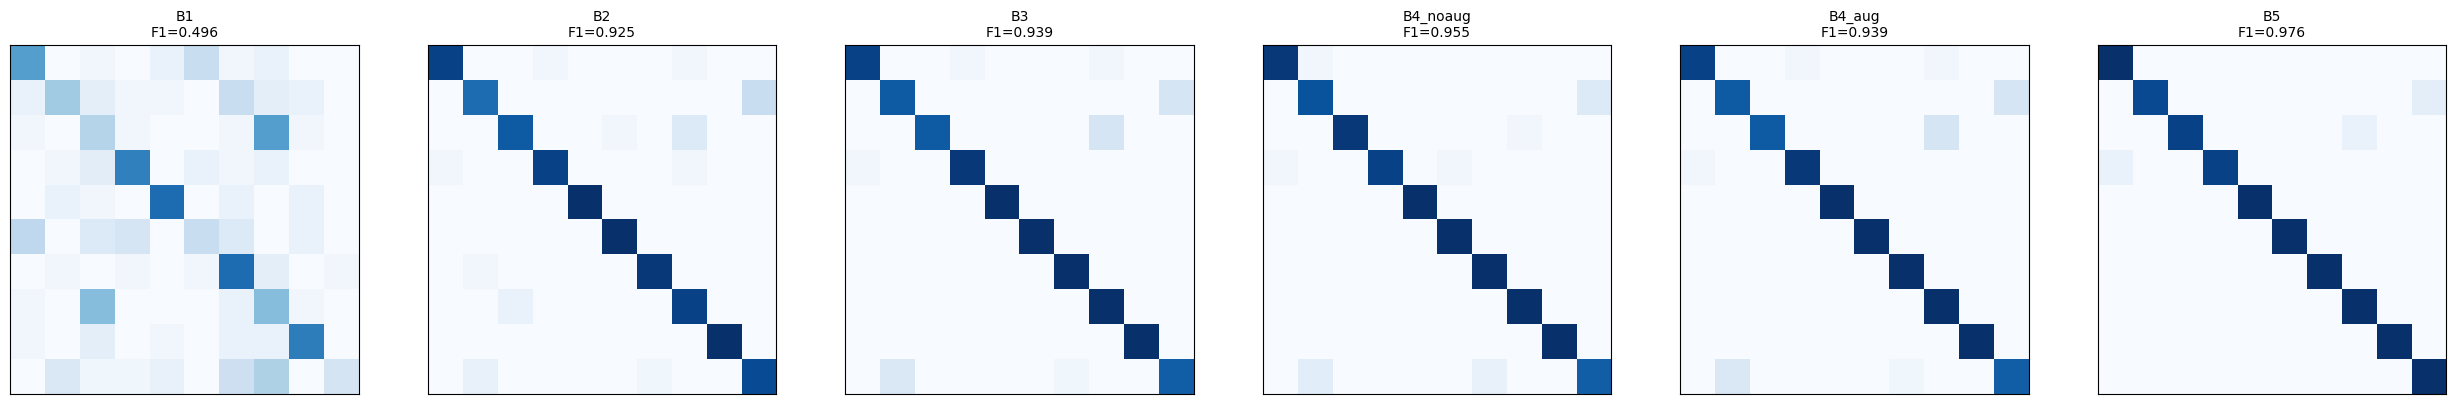

In [24]:
# Confusion matrix semua kondisi (lampiran)
n = len(ORDER); fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4))
for ax, c in zip(np.atleast_1d(axes), ORDER):
    m = np.array(RESULTS[c]["test_confusion_matrix"]); ax.imshow(m / m.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{c}\nF1={RESULTS[c]['test_macro_f1']:.3f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices_all.png", dpi=120); plt.show()

## 20. Failure analysis (C3) — sampel **test set** yang salah diklasifikasikan oleh model terbaik
Aturan pemilihan sampel (deterministik): semua prediksi salah diurutkan berdasarkan *confidence* dari yang tertinggi (*confidently wrong*), lalu diambil 8 teratas. Confidence = `softmax(logits)[pred]` dari output model pada checkpoint terpilih.

Citra ditampilkan **persis seperti yang dilihat model**, yaitu setelah `Resize(256)` + `CenterCrop(224)` dan tanpa augmentasi, karena center crop dapat memotong bagian penting seperti wajah. Di sebelahnya ditampilkan satu citra *train* dari kelas prediksi. Citra ini hanya pembanding visual untuk menyusun hipotesis dan tidak dipakai untuk evaluasi.

Kolom **hipotesis** di `failure_cases_<kode>.csv` sengaja dikosongkan untuk diisi sendiri berdasarkan pengamatan visual.

**Jika model terbaik membuat kurang dari 5 kesalahan:** tidak ada data yang dibuat-buat. Semua misklasifikasi ditampilkan apa adanya, jumlahnya dicatat di `failure_summary_<kode>.json`, dan sebagai *pelengkap* ditampilkan prediksi **benar** dengan probabilitas kelas benar terendah. Kasus pelengkap diberi label jelas sebagai bukan misklasifikasi. Laporkan kondisi ini secara terbuka di C3.

Jumlah misklasifikasi B5 pada test: 7 dari 297


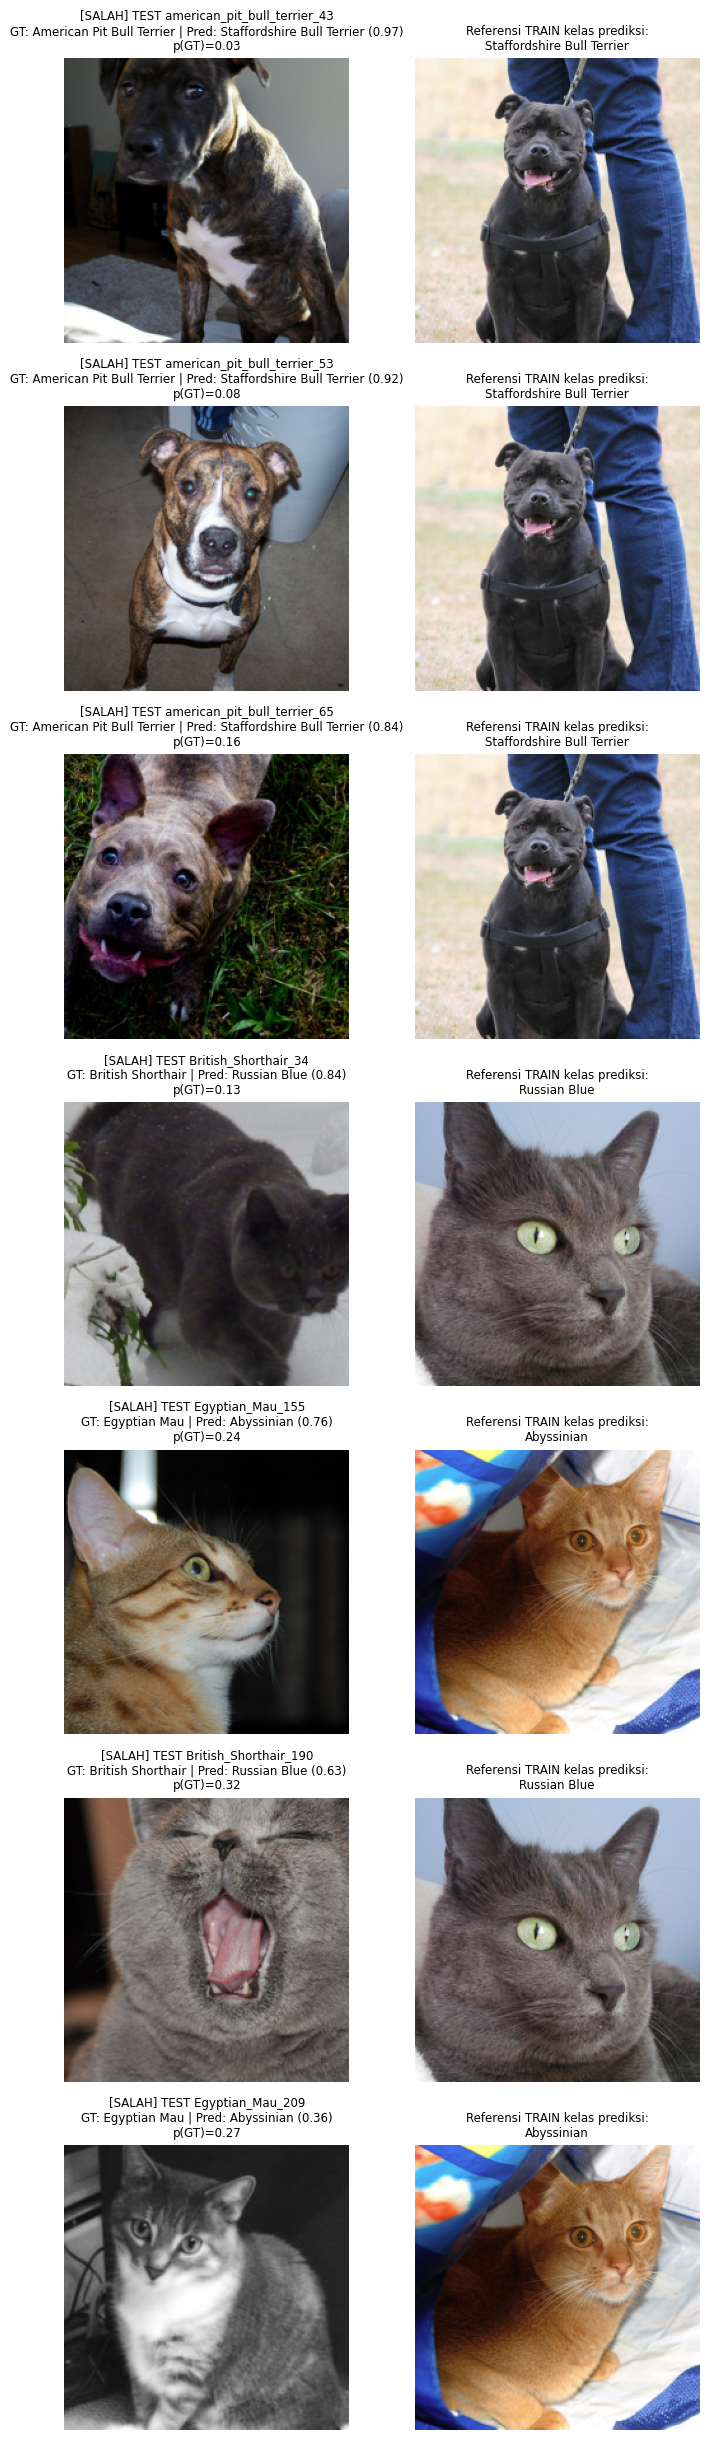

{'best_code': 'B5', 'n_test': 297, 'n_misclassified': 7, 'n_misclassified_shown': 7, 'n_supplementary_correct_shown': 0, 'selection_rule': 'misklasifikasi diurutkan confidence menurun, maks 8; bila <5, pelengkap = prediksi benar dengan p(GT) terendah'}


,jenis,image_id,true_name,pred_name,confidence,prob_true,top3
172,misklasifikasi,american_pit_bull_terrier_43,American Pit Bull Terrier,Staffordshire Bull Terrier,0.966861,0.033062,Staffordshire Bull Terrier 0.97; American Pit ...
176,misklasifikasi,american_pit_bull_terrier_53,American Pit Bull Terrier,Staffordshire Bull Terrier,0.922531,0.077425,Staffordshire Bull Terrier 0.92; American Pit ...
177,misklasifikasi,american_pit_bull_terrier_65,American Pit Bull Terrier,Staffordshire Bull Terrier,0.841602,0.158374,Staffordshire Bull Terrier 0.84; American Pit ...
189,misklasifikasi,British_Shorthair_34,British Shorthair,Russian Blue,0.836356,0.127046,Russian Blue 0.84; British Shorthair 0.13; Sta...
101,misklasifikasi,Egyptian_Mau_155,Egyptian Mau,Abyssinian,0.757352,0.239345,Abyssinian 0.76; Egyptian Mau 0.24; Maine Coon...
96,misklasifikasi,British_Shorthair_190,British Shorthair,Russian Blue,0.630582,0.324226,Russian Blue 0.63; British Shorthair 0.32; Sta...
199,misklasifikasi,Egyptian_Mau_209,Egyptian Mau,Abyssinian,0.364420,0.268382,Abyssinian 0.36; Maine Coon 0.33; Egyptian Mau...


In [25]:
P = PREDS[BEST_CODE]
assert set(P.row_idx) == S_te, "Prediksi yang dianalisis harus berasal dari test set!"
wrong = P[P.y_true != P.y_pred].sort_values("confidence", ascending=False)
N_WRONG = len(wrong)
print(f"Jumlah misklasifikasi {BEST_CODE} pada test: {N_WRONG} dari {len(P)}")

FAIL = wrong.head(8).copy()
FAIL["jenis"] = "misklasifikasi"
SUPP = P.iloc[0:0].copy()
if N_WRONG < 5:
    # Tidak ada data yang dibuat-buat: semua misklasifikasi ditampilkan apa adanya. Sebagai PELENGKAP
    # (bukan pengganti), ditampilkan prediksi BENAR dengan p(GT) terendah dari model & test set yang sama,
    # diberi label jelas. Laporkan di C3 bahwa model hanya membuat N_WRONG kesalahan.
    warnings.warn(f"Model terbaik hanya membuat {N_WRONG} misklasifikasi (<5). Semua ditampilkan; "
                  f"{5 - N_WRONG} kasus pelengkap = prediksi BENAR paling tidak yakin (diberi label).")
    SUPP = P[P.y_true == P.y_pred].sort_values("prob_true", ascending=True).head(5 - N_WRONG).copy()
    SUPP["jenis"] = "pelengkap: prediksi BENAR dengan p(GT) terendah"
CASES = pd.concat([FAIL, SUPP])
view_tf = transforms.Compose([transforms.Resize(CFG["resize"]), transforms.CenterCrop(CFG["img_size"])])

def top3(r):
    p = np.array([r[f"p_{c}"] for c in range(NUM_CLASSES)])
    o = np.argsort(-p)[:3]
    return "; ".join(f"{CLASS_NAMES[k]} {p[k]:.2f}" for k in o)

if len(CASES):
    CASES["true_name"] = CASES.y_true.map(lambda k: CLASS_NAMES[k])
    CASES["pred_name"] = CASES.y_pred.map(lambda k: CLASS_NAMES[k])
    CASES["top3"] = CASES.apply(top3, axis=1)
    CASES["path"] = CASES.row_idx.map(lambda i: df.path[i])
    assert set(CASES.row_idx) <= S_te, "Sampel failure analysis harus berasal dari test set!"
    CASES["hipotesis_penyebab"] = ""   # <-- DIISI MAHASISWA setelah mengamati citra
    CASES[["jenis", "row_idx", "image_id", "true_name", "pred_name", "confidence", "prob_true", "top3", "hipotesis_penyebab"]].to_csv(
        RES_DIR / f"failure_cases_{BEST_CODE}.csv", index=False)

    k = len(CASES)
    fig, axes = plt.subplots(k, 2, figsize=(7.5, 3.5 * k), squeeze=False)
    for r, (_, row) in enumerate(CASES.iterrows()):
        tag = "SALAH" if row.jenis == "misklasifikasi" else "BENAR (pelengkap, bukan misklasifikasi)"
        axes[r, 0].imshow(view_tf(Image.open(row.path).convert("RGB")))
        axes[r, 0].set_title(f"[{tag}] TEST {row.image_id}\nGT: {row.true_name} | Pred: {row.pred_name} ({row.confidence:.2f})\n"
                             f"p(GT)={row.prob_true:.2f}", fontsize=8.5)
        ref = df[(df.split == "train") & (df.label == row.y_pred)].iloc[0]
        axes[r, 1].imshow(view_tf(Image.open(ref.path).convert("RGB")))
        axes[r, 1].set_title(f"Referensi TRAIN kelas prediksi:\n{ref.class_name}", fontsize=8.5)
        for a in axes[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"failure_cases_{BEST_CODE}.png", dpi=110); plt.show()
else:
    print("Tidak ada kasus untuk ditampilkan.")

FAILURE_SUMMARY = {"best_code": BEST_CODE, "n_test": int(len(P)), "n_misclassified": int(N_WRONG),
                   "n_misclassified_shown": int(len(FAIL)), "n_supplementary_correct_shown": int(len(SUPP)),
                   "selection_rule": "misklasifikasi diurutkan confidence menurun, maks 8; bila <5, pelengkap = prediksi benar dengan p(GT) terendah"}
with open(RES_DIR / f"failure_summary_{BEST_CODE}.json", "w") as f:
    json.dump(FAILURE_SUMMARY, f, indent=2)
print(FAILURE_SUMMARY)
CASES[["jenis", "image_id", "true_name", "pred_name", "confidence", "prob_true", "top3"]] if len(CASES) else None

## 21. C5 (opsional) — Grad-CAM pada `layer4`: sebelum vs sesudah fine-tuning
* **Sebelum fine-tuning:** model **B2**. Backbone-nya = `layer4` ImageNet asli (terverifikasi tidak berubah), dengan head 10 kelas.
* **Sesudah fine-tuning:** model **B3** (`layer4` disesuaikan pada data Pet).

Keduanya memakai arsitektur dan tugas yang sama, sehingga peta Grad-CAM untuk kelas *ground truth* bisa dibandingkan langsung. Implementasi Grad-CAM ditulis manual (Selvaraju et al., 2017): bobot kanal = rata-rata gradien skor kelas terhadap aktivasi `layer4`, lalu ReLU dari kombinasi linear aktivasi.

Sebagai pelengkap kuantitatif, dihitung *linear CKA* (Kornblith et al., 2019) antara fitur pooled `layer4` B2 dan B3 pada test set. Nilai 1 berarti representasinya identik sampai transformasi ortogonal/skala.

**Keterbatasan interpretasi:** Grad-CAM beresolusi kasar (7×7 di-upsample), menunjukkan *korelasi* gradien dan bukan penyebab, serta bisa berbeda untuk kelas target yang berbeda. Gunakan sebagai ilustrasi kualitatif, bukan bukti.

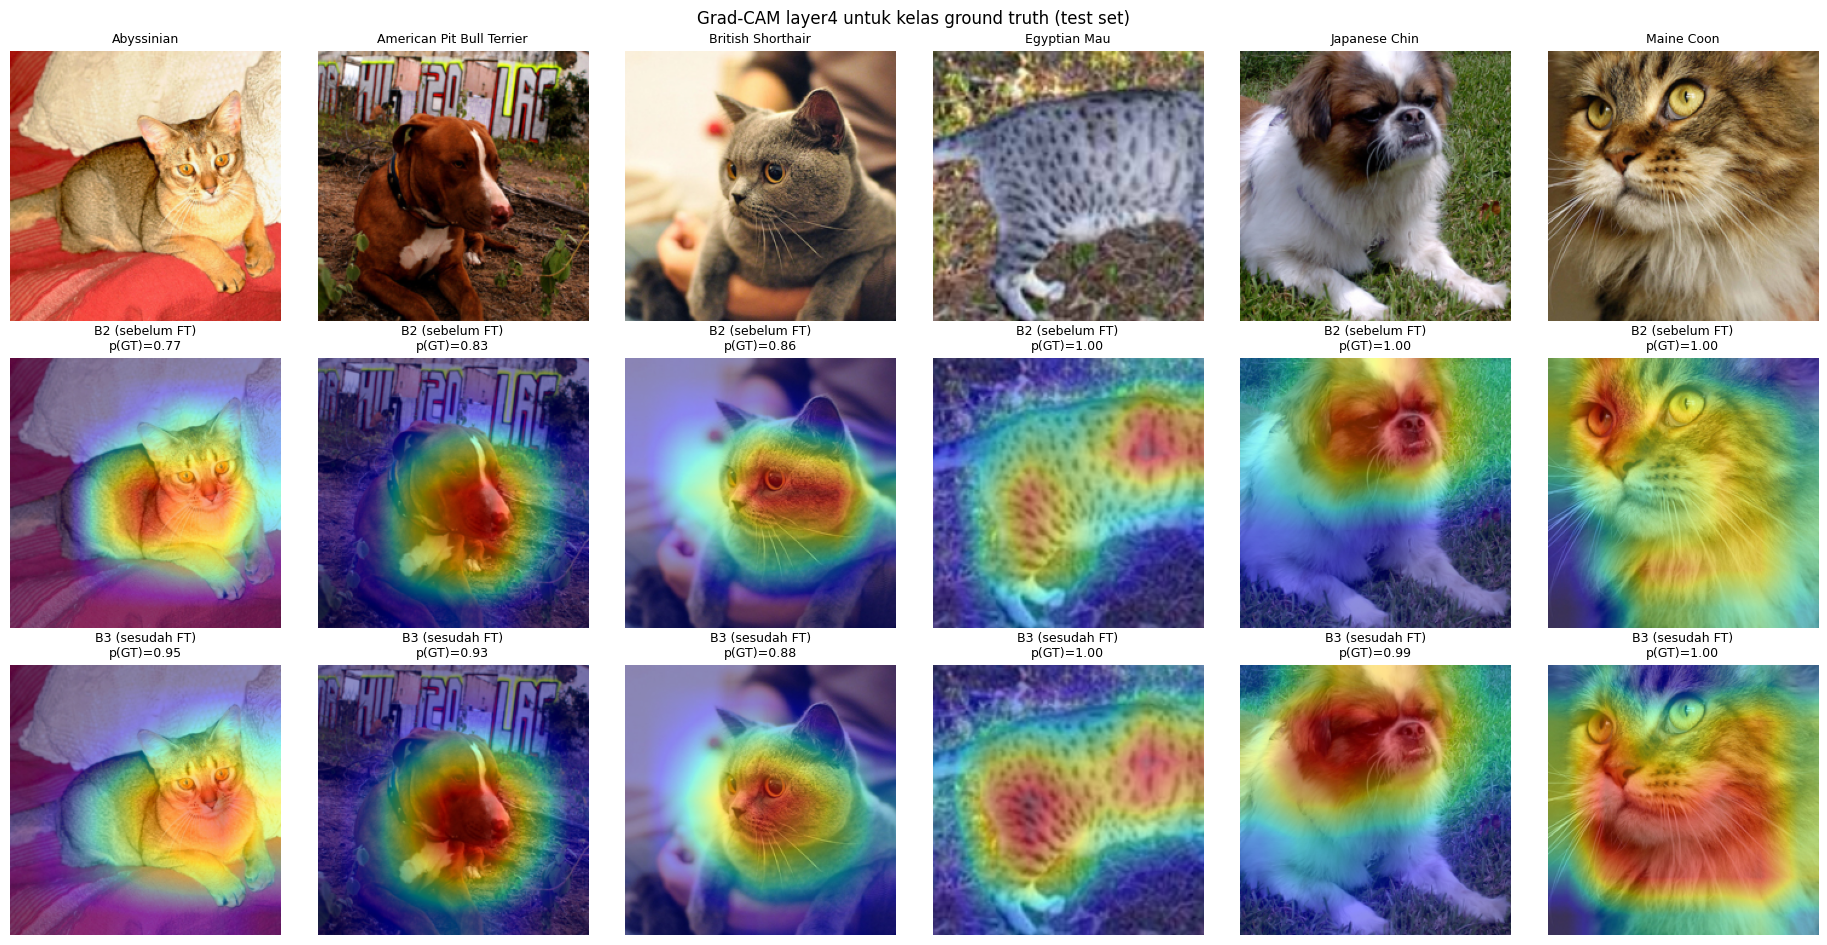

Linear CKA fitur pooled layer4, B2 (pretrained) vs B3 (fine-tuned), test set: 0.8375
Status C5: {'run': True, 'ok': True, 'error': None}


In [26]:
def load_trained(code):
    s = RESULTS[code]
    m = build_model(s["arch"], pretrained=False)   # bobot diisi dari checkpoint
    m.load_state_dict(torch.load(CKPT_DIR / f"{code}_best.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


def grad_cam(model, x, class_idx, layer):
    store = {}
    def fwd_hook(m, i, o):
        store["act"] = o
        o.register_hook(lambda g: store.__setitem__("grad", g))
    h = layer.register_forward_hook(fwd_hook)
    x = x.clone().requires_grad_(True)       # agar gradien mengalir walau layer dibekukan
    model.zero_grad(set_to_none=True)
    out = model(x)
    out[0, class_idx].backward()
    h.remove()
    a, g = store["act"][0].detach(), store["grad"][0].detach()
    cam = F.relu((g.mean(dim=(1, 2), keepdim=True) * a).sum(0))
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy(), out.softmax(1)[0].detach().cpu().numpy()


@torch.no_grad()
def pooled_layer4(model, loader):
    feats, h = [], model.layer4.register_forward_hook(lambda m, i, o: feats.append(o.mean((2, 3)).cpu()))
    for x, _, _ in loader:
        model(x.to(DEVICE))
    h.remove()
    return torch.cat(feats).double()


def linear_cka(X, Y):
    X, Y = X - X.mean(0), Y - Y.mean(0)
    return ((Y.T @ X).norm() ** 2 / ((X.T @ X).norm() * (Y.T @ Y).norm())).item()


def run_c5():
    if "C5" in SIMULATE_FAIL:
        raise RuntimeError("[SMOKE] kegagalan C5 disimulasikan")
    m_before, m_after = load_trained("B2"), load_trained("B3")
    # 6 citra test pertama dari 6 kelas berbeda (aturan deterministik; bukan dipilih berdasarkan hasil)
    picks = df[df.split == "test"].drop_duplicates("label").head(6)
    fig, axes = plt.subplots(3, len(picks), figsize=(3.1 * len(picks), 9.6))
    for j, (i, row) in enumerate(picks.iterrows()):
        img = IMAGES[i] if IMAGES is not None else Image.open(row.path).convert("RGB")
        x = eval_tf(img)[None].to(DEVICE)
        view = denorm(eval_tf(img))
        cam_b, p_b = grad_cam(m_before, x, int(row.label), m_before.layer4)
        cam_a, p_a = grad_cam(m_after, x, int(row.label), m_after.layer4)
        axes[0, j].imshow(view); axes[0, j].set_title(f"{row.class_name}", fontsize=9)
        axes[1, j].imshow(view); axes[1, j].imshow(cam_b, cmap="jet", alpha=0.45)
        axes[1, j].set_title(f"B2 (sebelum FT)\np(GT)={p_b[row.label]:.2f}", fontsize=9)
        axes[2, j].imshow(view); axes[2, j].imshow(cam_a, cmap="jet", alpha=0.45)
        axes[2, j].set_title(f"B3 (sesudah FT)\np(GT)={p_a[row.label]:.2f}", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    plt.suptitle("Grad-CAM layer4 untuk kelas ground truth (test set)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_layer4_B2_vs_B3.png", dpi=120); plt.show()

    test_loader = make_loaders(eval_tf)["test"]
    fb, fa = pooled_layer4(m_before, test_loader), pooled_layer4(m_after, test_loader)
    cka = linear_cka(fb, fa)
    print(f"Linear CKA fitur pooled layer4, B2 (pretrained) vs B3 (fine-tuned), test set: {cka:.4f}")
    with open(RES_DIR / "c5_cka.json", "w") as f:
        json.dump({"linear_cka_layer4_B2_vs_B3_test": cka}, f, indent=2)


# C5 opsional: kegagalan dicatat lalu dilewati agar sel ekspor tetap berjalan.
C5_STATUS = {"run": CFG["run_c5"], "ok": False, "error": None}
if CFG["run_c5"] and all(c in RESULTS for c in ["B2", "B3"]):
    try:
        run_c5()
        C5_STATUS["ok"] = True
    except Exception as e:
        C5_STATUS["error"] = f"{type(e).__name__}: {e}"
        warnings.warn(f"C5 gagal dan DILEWATI: {C5_STATUS['error']}")
        plt.close("all")
else:
    print("C5 dilewati.")
with open(RES_DIR / "c5_status.json", "w") as f:
    json.dump(C5_STATUS, f, indent=2)
print("Status C5:", C5_STATUS)

## 22. Ekspor artefak dan pemeriksaan kualitas otomatis

In [27]:
try:
    from importlib.metadata import version
    pkgs = ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "matplotlib", "pillow", "tabulate"]
    with open(RES_DIR / "environment_versions.txt", "w") as f:
        for p in pkgs:
            try: f.write(f"{p}=={version(p)}\n")
            except Exception: f.write(f"# {p}: tidak terpasang\n")
except Exception as e:
    print("Gagal mencatat versi paket:", e)

checks = []
def check(name, ok, info=None):
    checks.append({"pemeriksaan": name, "status": "PASS" if ok else (info or "FAIL")})

check("Bukan smoke test (hasil berasal dari dataset & bobot asli)", not SMOKE_TEST)
check("GPU dipakai", DEVICE.type == "cuda")
check("B1-B4 lengkap", all(c in RESULTS for c in ["B1", "B2", "B3", "B4_noaug", "B4_aug"]))
check("B1 tanpa pretrained; B2/B3/B4 pretrained", (not RESULTS["B1"]["pretrained"]) and all(RESULTS[c]["pretrained"] for c in ["B2", "B3", "B4_noaug", "B4_aug"]))
check("Trainable params B1/B2/B3 = 11.181.642 / 5.130 / 8.398.858",
      [RESULTS[c]["trainable_params"] for c in ["B1", "B2", "B3"]] == [11_181_642, 5_130, 8_398_858])
check("LR B3: layer4=1e-4, fc=1e-3", RESULTS["B3"]["lr_per_group"] == {"layer4": 1e-4, "fc": 1e-3})
check("Split saling lepas & stratified (assert lulus)", True)
check("Test dievaluasi sekali per kondisi", all(RESULTS[c]["test_evaluated_once"] for c in ORDER))
check("Macro F1 di summary == dihitung ulang dari prediksi", all(
    abs(f1_score(PREDS[c].y_true, PREDS[c].y_pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0) - RESULTS[c]["test_macro_f1"]) < 1e-9 for c in ORDER))
check("summary.csv cocok dengan summary JSON", all(
    abs(pd.read_csv(RES_DIR / "summary.csv").set_index("Kode").loc[c, "Test Macro F1"] - round(RESULTS[c]["test_macro_f1"], 4)) < 1e-9 for c in ORDER))
check("Failure analysis: semua sampel berasal dari test set", set(CASES.row_idx) <= S_te)
check("Failure analysis: >=5 misklasifikasi tersedia", N_WRONG >= 5,
      info=f"INFO: hanya {N_WRONG} misklasifikasi; dilaporkan apa adanya + {len(SUPP)} kasus pelengkap berlabel")
check("B5 (bonus) selesai", B5_STATUS["ok"], info="INFO: B5 dilewati/gagal (lihat b5_status.json)")
check("C5 (opsional) selesai", C5_STATUS["ok"], info="INFO: C5 dilewati/gagal (lihat c5_status.json)")
qc = pd.DataFrame(checks); qc.to_csv(RES_DIR / "quality_checks.csv", index=False)
print(qc.to_string(index=False))

with open(RES_DIR / "run_manifest.json", "w") as f:
    json.dump({"finished_at": time.strftime("%Y-%m-%d %H:%M:%S"), "conditions": ORDER, "best_by_val": BEST_CODE,
               "smoke_test": SMOKE_TEST, "env": ENV_INFO, "split_hash": split_hash,
               "summary_csv_sha256": hashlib.sha256((RES_DIR / "summary.csv").read_bytes()).hexdigest()}, f, indent=2)

# Bundel hasil (tanpa checkpoint) untuk laporan & ZIP pengumpulan
import zipfile
with zipfile.ZipFile(OUT_DIR / "outputs_bundle.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ["results", "figures"]:
        for p in sorted((OUT_DIR / sub).rglob("*")):
            if p.is_file():
                z.write(p, p.relative_to(OUT_DIR))
print("Bundel:", OUT_DIR / "outputs_bundle.zip")
for sub in ["results", "figures"]:
    print(f"\n{sub}/"); [print("  ", p.name) for p in sorted((OUT_DIR / sub).iterdir())]

if IN_COLAB:
    try:
        from google.colab import files
        files.download(str(OUT_DIR / "outputs_bundle.zip"))
    except Exception as e:
        print("Unduh manual dari Drive:", e)

                                               pemeriksaan status
Bukan smoke test (hasil berasal dari dataset & bobot asli)   PASS
                                               GPU dipakai   PASS
                                             B1-B4 lengkap   PASS
                  B1 tanpa pretrained; B2/B3/B4 pretrained   PASS
Trainable params B1/B2/B3 = 11.181.642 / 5.130 / 8.398.858   PASS
                               LR B3: layer4=1e-4, fc=1e-3   PASS
            Split saling lepas & stratified (assert lulus)   PASS
                        Test dievaluasi sekali per kondisi   PASS
       Macro F1 di summary == dihitung ulang dari prediksi   PASS
                     summary.csv cocok dengan summary JSON   PASS
      Failure analysis: semua sampel berasal dari test set   PASS
             Failure analysis: >=5 misklasifikasi tersedia   PASS
                                        B5 (bonus) selesai   PASS
                                     C5 (opsional) selesai   PASS
Bundel: /c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Ringkasan temuan empiris
Sel di bawah hanya mencetak **fakta** dari log (angka), tanpa interpretasi. Interpretasi, analisis komparatif, dan kesimpulan **wajib ditulis sendiri oleh mahasiswa** (kebijakan AI §7 pada PDF tugas).

In [28]:
for c in ORDER:
    s = RESULTS[c]
    print(f"{c:9s} | {s['strategy']:18s} aug={s['augmentation']:5s} | trainable={s['trainable_params']:>10,} | "
          f"best_ep={s['best_epoch']:2d}/{s['epochs_run']:2d} | {s['duration_s']:7.1f}s | val_acc={s['val_acc']:.4f} | "
          f"gap={s['gap_acc_clean_train_minus_val']:+.4f} | test_acc={s['test_acc']:.4f} | test_F1={s['test_macro_f1']:.4f}")
print("\nModel terbaik berdasarkan validation:", BEST_CODE)

B1        | scratch            aug=aug   | trainable=11,181,642 | best_ep=15/20 |   168.5s | val_acc=0.5320 | gap=+0.0551 | test_acc=0.5017 | test_F1=0.4957
B2        | feature_extraction aug=aug   | trainable=     5,130 | best_ep=22/27 |   188.8s | val_acc=0.9428 | gap=+0.0088 | test_acc=0.9259 | test_F1=0.9254
B3        | finetune_last      aug=aug   | trainable= 8,398,858 | best_ep= 3/ 8 |    55.2s | val_acc=0.9428 | gap=+0.0355 | test_acc=0.9394 | test_F1=0.9385
B4_noaug  | finetune_last      aug=noaug | trainable= 8,398,858 | best_ep= 8/13 |    42.6s | val_acc=0.9596 | gap=+0.0404 | test_acc=0.9562 | test_F1=0.9552
B4_aug    | finetune_last      aug=aug   | trainable= 8,398,858 | best_ep= 3/ 8 |    55.6s | val_acc=0.9428 | gap=+0.0355 | test_acc=0.9394 | test_F1=0.9385
B5        | finetune_last      aug=noaug | trainable= 3,168,550 | best_ep= 5/10 |    43.0s | val_acc=0.9630 | gap=+0.0370 | test_acc=0.9764 | test_F1=0.9762

Model terbaik berdasarkan validation: B5


**Interpretasi (diisi mahasiswa):**

1. B1 vs B2/B3: *[DIISI MAHASISWA berdasarkan tabel & kurva di atas]*
2. B2 vs B3 (performa vs stabilitas): *[DIISI MAHASISWA]*
3. B4 (pengaruh augmentasi terhadap gap): *[DIISI MAHASISWA]*
4. B5 (trade-off efisiensi): *[DIISI MAHASISWA]*
5. Limitasi: *[DIISI MAHASISWA]*